## PART 1: Load Pre-trained U-Net
(Same as original – kept for completeness)

In [1]:
from pathlib import Path
import torch

DATA_ROOT  = Path('/data')
IMAGES_DIR = DATA_ROOT / 'train'
MASKS_DIR  = DATA_ROOT / 'train_masks'

LOCAL_CHECKPOINT_PATH = Path('weights/unet_carvana_scale0.5_epoch2.pth')
IMG_SIZE = (512, 512)
DEVICE   = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('Using device:', DEVICE)
print('Checkpoint:  ', LOCAL_CHECKPOINT_PATH.resolve())

Using device: cuda
Checkpoint:   /home/jovyan/cost-based-pruning-layer-by-layer/weights/unet_carvana_scale0.5_epoch2.pth


In [2]:
import sys
import torch.nn as nn

REPO_ROOT = Path('/home/jovyan/pruning-datavol-1/Pytorch-UNet')
sys.path.append(str(REPO_ROOT))

from unet.unet_model import UNet

def load_unet_model_local_from_checkpoint(checkpoint_path, device):
    model = UNet(n_channels=3, n_classes=2, bilinear=False)
    state = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
    for key in ('mask_values', ):
        state.pop(key, None)
    if 'model_state_dict' in state:
        state = state['model_state_dict']
    elif 'state_dict' in state:
        state = state['state_dict']
    model.load_state_dict(state)
    model.to(device).eval()
    for p in model.parameters():
        p.requires_grad = False
    return model

model = load_unet_model_local_from_checkpoint(LOCAL_CHECKPOINT_PATH, DEVICE)

## PART 2: Layer-by-Layer Profiling (Global Ranking + Part Reference)

### Strategy
Instead of allocating pruning budgets to *macro-sections* (encoder / bottleneck / decoder),
we profile **every individual Conv2d layer** in the network and rank them globally
by cost (parameters, FLOPs, latency).  
Each layer is also tagged with the U-Net part it belongs to
(`encoder | bottleneck | decoder | out_conv`) so pruning decisions can be made
globally while still having a structural reference for interpretation.


### 2.1  Profiling configuration

In [3]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# ── Central config ─────────────────────────────────────────────────────────
PROFILE_INPUT_SIZE = (1, 3, 512, 512)   # (N, C, H, W) — must match real images

# Number of random images sampled from each dataset for profiling.
# Timings are averaged across all images → more images = more stable estimates.
N_IMAGES_PER_DATASET = 8    # increase for even more stability (costs time)

# Warmup runs before timing (per layer, per image)
N_WARMUP = 10

# Timing runs per layer per image — total runs = N_RUNS × total_images
N_RUNS   = 50

DEVICE_GPU = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DEVICE_CPU = torch.device('cpu')

# ── Dataset directories ────────────────────────────────────────────────────
# Both datasets are used: activations are captured from real images of each,
# then timings are averaged across all images for stable, input-agnostic results.
CARVANA_IMGS_DIR = Path('data/train')          # .jpg images
#MRI_IMGS_DIR     = Path('../Pytorch-UNet/dataset_split/train/imgs')  # .tif images

# ── Part map ───────────────────────────────────────────────────────────────
PART_MAP = {
    'inc'  : 'encoder',
    'down1': 'encoder',
    'down2': 'encoder',
    'down3': 'encoder',
    'down4': 'bottleneck',
    'up1'  : 'decoder',
    'up2'  : 'decoder',
    'up3'  : 'decoder',
    'up4'  : 'decoder',
    'outc' : 'out_conv',
}

print('Profiling config')
print('  Input size          :', PROFILE_INPUT_SIZE)
print('  Images per dataset  :', N_IMAGES_PER_DATASET)
print('  Warmup runs         :', N_WARMUP)
print('  Timing runs/image   :', N_RUNS)
print('  Total timing runs   :', N_RUNS * N_IMAGES_PER_DATASET * 2, '(×2 datasets)')
print('  GPU device          :', DEVICE_GPU)


Profiling config
  Input size          : (1, 3, 512, 512)
  Images per dataset  : 8
  Warmup runs         : 10
  Timing runs/image   : 50
  Total timing runs   : 800 (×2 datasets)
  GPU device          : cuda


### 2.2  FLOPs helpers

In [4]:
def conv2d_flops(conv: nn.Conv2d, h: int, w: int) -> int:
    """MACs × 2 for Conv2d (multiply + add)."""
    kh, kw = conv.kernel_size
    return int(2 * (conv.in_channels // conv.groups) * kh * kw
               * conv.out_channels * h * w)

def convtranspose2d_flops(conv_t: nn.ConvTranspose2d, h_out: int, w_out: int) -> int:
    """MACs × 2 for ConvTranspose2d; h_out, w_out are OUTPUT spatial dims."""
    kh, kw = conv_t.kernel_size
    return int(2 * (conv_t.in_channels // conv_t.groups) * kh * kw
               * conv_t.out_channels * h_out * w_out)

### 2.3  Capture output shapes via forward hooks

In [5]:
def capture_output_shapes(model: nn.Module,
                          input_size=(1, 3, 128, 128),
                          device=None) -> dict:
    """Returns {module_name -> (N,C,H,W)} for every module in the network."""
    if device is None:
        device = next(model.parameters()).device

    shapes = {}
    hooks  = []

    def _hook(name):
        def _fn(_m, _inp, out):
            t = out if isinstance(out, torch.Tensor) else (out[0] if out else None)
            shapes[name] = tuple(t.shape) if t is not None else None
        return _fn

    for name, m in model.named_modules():
        if name:
            hooks.append(m.register_forward_hook(_hook(name)))

    model.to(device).eval()
    with torch.no_grad():
        model(torch.randn(*input_size, device=device))

    for h in hooks:
        h.remove()

    return shapes


output_shapes = capture_output_shapes(model, PROFILE_INPUT_SIZE, DEVICE_GPU)
print(f'Captured shapes for {len(output_shapes)} modules.')

Captured shapes for 94 modules.


### 2.4  Per-layer latency measurement (GPU & CPU)

In [6]:
import random
from PIL import Image
import torchvision.transforms.functional as TF

# ── Image loading helpers ──────────────────────────────────────────────────

def load_image_as_tensor(img_path: Path,
                         target_size=(512, 512)) -> torch.Tensor:
    """
    Load any image (jpg, tif, png …) and return a normalised
    (1, 3, H, W) float32 tensor ready for the model.
    Grayscale images are replicated to 3 channels.
    """
    img = Image.open(img_path).convert('RGB')
    img = img.resize((target_size[1], target_size[0]), Image.BILINEAR)
    t = TF.to_tensor(img)          # (3, H, W) in [0, 1]
    return t.unsqueeze(0)          # (1, 3, H, W)


def sample_images(img_dir: Path,
                  n: int,
                  extensions=('.jpg', '.jpeg', '.png', '.tif', '.tiff'),
                  seed: int = 42) -> list:
    """
    Randomly sample up to n image paths from img_dir.
    Returns fewer if the directory has fewer images.
    """
    if not img_dir.exists():
        print(f'  WARNING: directory not found: {img_dir}')
        return []
    paths = [p for p in img_dir.iterdir()
             if p.suffix.lower() in extensions]
    if not paths:
        print(f'  WARNING: no images found in {img_dir}')
        return []
    random.seed(seed)
    sampled = random.sample(paths, min(n, len(paths)))
    return sampled


def build_input_list(carvana_dir: Path,
                     mri_dir: Path,
                     n_per_dataset: int,
                     target_hw: tuple) -> list:
    """
    Sample images from both datasets and return a list of
    (1, 3, H, W) tensors on CPU.
    """
    tensors = []
    for dataset_name, img_dir in [('carvana', carvana_dir),
                                   ('mri',     mri_dir)]:
        paths = sample_images(img_dir, n_per_dataset)
        print(f'  {dataset_name}: {len(paths)} images sampled from {img_dir}')
        for p in paths:
            try:
                t = load_image_as_tensor(p, target_size=target_hw)
                tensors.append(t)
            except Exception as e:
                print(f'    WARNING: could not load {p.name}: {e}')
    print(f'  Total input images for profiling: {len(tensors)}')
    return tensors


# ── Core profiling functions ───────────────────────────────────────────────

def measure_layer_latency(layer: nn.Module,
                          input_tensor: torch.Tensor,
                          device: torch.device,
                          n_warmup: int = 10,
                          n_runs: int = 50) -> float:
    """Average forward time in ms for one layer on one input."""
    layer = layer.to(device).eval()
    x = input_tensor.to(device)

    def sync():
        if device.type == 'cuda':
            torch.cuda.synchronize()

    with torch.no_grad():
        for _ in range(n_warmup):
            _ = layer(x)
        sync()
        t0 = time.perf_counter()
        for _ in range(n_runs):
            _ = layer(x)
        sync()
        t1 = time.perf_counter()

    return (t1 - t0) * 1000.0 / n_runs


def capture_real_inputs_for_image(model: nn.Module,
                                  image_tensor: torch.Tensor,
                                  device: torch.device) -> dict:
    """
    Run one forward pass with a specific image tensor and capture
    the actual activation entering each Conv2d / ConvTranspose2d.
    Returns {layer_name -> cpu tensor}.
    """
    real_inputs = {}
    hooks = []

    def _hook(name):
        def _fn(_m, inp, _out):
            t = inp[0] if isinstance(inp, (tuple, list)) else inp
            if isinstance(t, torch.Tensor):
                real_inputs[name] = t.detach().cpu().clone()
        return _fn

    for name, m in model.named_modules():
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            hooks.append(m.register_forward_hook(_hook(name)))

    model.to(device).eval()
    with torch.no_grad():
        model(image_tensor.to(device))

    for h in hooks:
        h.remove()

    return real_inputs


def profile_all_conv_layers(model: nn.Module,
                            output_shapes: dict,
                            input_tensors: list,
                            device_gpu=None,
                            device_cpu=None,
                            part_map: dict = None,
                            n_warmup: int = 10,
                            n_runs: int = 50) -> pd.DataFrame:
    """
    Profile every Conv2d / ConvTranspose2d using REAL activations from
    multiple input images (from both datasets).

    For each layer:
      - timing is run separately for every image
      - GPU and CPU times are averaged across all images
      → reduces variance from input-specific activation patterns

    Returns one DataFrame row per layer.
    """
    if device_gpu is None:
        device_gpu = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    if device_cpu is None:
        device_cpu = torch.device('cpu')
    if part_map is None:
        part_map = {}

    n_images = len(input_tensors)
    assert n_images > 0, "input_tensors list is empty — check dataset paths."

    def _to_int_tuple(v):
        if isinstance(v, (tuple, list)):
            return tuple(int(x) for x in v)
        return (int(v), int(v))

    # ── Step 1: capture real inputs for every image ────────────────────────
    print(f'  [1/2] Capturing real activations for {n_images} images ...')
    # all_real_inputs[img_idx][layer_name] = cpu tensor
    all_real_inputs = []
    for i, img_t in enumerate(input_tensors):
        print(f'    image {i+1}/{n_images} ...', end=' ', flush=True)
        ri = capture_real_inputs_for_image(model, img_t, device_gpu)
        all_real_inputs.append(ri)
        print(f'ok ({len(ri)} layers captured)')

    # ── Step 2: time each layer, averaging over all images ────────────────
    print(f'\n  [2/2] Timing each layer ({n_runs} runs × {n_images} images) ...')

    conv_layers = [(name, m) for name, m in model.named_modules()
                   if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d))]
    n_total = len(conv_layers)

    rows = []
    for idx, (name, m) in enumerate(conv_layers):
        is_conv   = isinstance(m, nn.Conv2d)
        is_deconv = isinstance(m, nn.ConvTranspose2d)

        oshape = output_shapes.get(name)
        if oshape is None or len(oshape) < 4:
            continue
        _, c_out, h_out, w_out = oshape

        top_level = name.split('.')[0]
        part = part_map.get(top_level, 'unknown')

        n_params = sum(p.numel() for p in m.parameters(recurse=False))

        if is_conv:
            flops = conv2d_flops(m, h_out, w_out)
        else:
            flops = convtranspose2d_flops(m, h_out, w_out)

        # Collect per-image timings
        gpu_times = []
        cpu_times = []
        real_in_shape = None

        for img_ri in all_real_inputs:
            x_real = img_ri.get(name)
            if x_real is None:
                continue
            if real_in_shape is None:
                real_in_shape = tuple(int(x) for x in x_real.shape)

            gpu_times.append(
                measure_layer_latency(m, x_real, device_gpu, n_warmup, n_runs)
            )
            cpu_times.append(
                measure_layer_latency(m, x_real, device_cpu, n_warmup, n_runs)
            )

        if not gpu_times:
            print(f'  WARNING: no inputs captured for {name}, skipping.')
            continue

        t_gpu_mean = float(np.mean(gpu_times))
        t_gpu_std  = float(np.std(gpu_times))
        t_cpu_mean = float(np.mean(cpu_times))
        t_cpu_std  = float(np.std(cpu_times))

        print(f'    ({idx+1}/{n_total}) {name:<50s}  '
              f'GPU={t_gpu_mean:.3f}±{t_gpu_std:.3f}ms  '
              f'CPU={t_cpu_mean:.3f}±{t_cpu_std:.3f}ms')

        rows.append({
            'layer_name'    : name,
            'part'          : part,
            'type'          : m.__class__.__name__,
            'in_ch'         : int(m.in_channels),
            'out_ch'        : int(m.out_channels),
            'kernel'        : _to_int_tuple(m.kernel_size),
            'stride'        : _to_int_tuple(m.stride),
            'padding'       : _to_int_tuple(m.padding),
            'real_in_shape' : real_in_shape,
            'out_h'         : int(h_out),
            'out_w'         : int(w_out),
            'out_shape'     : tuple(int(x) for x in oshape),
            'params'        : int(n_params),
            'params_M'      : n_params / 1e6,
            'flops'         : int(flops),
            'flops_M'       : flops / 1e6,
            'time_gpu_ms'   : t_gpu_mean,
            'time_gpu_std'  : t_gpu_std,
            'time_cpu_ms'   : t_cpu_mean,
            'time_cpu_std'  : t_cpu_std,
            'n_images'      : len(gpu_times),
        })

    return pd.DataFrame(rows)


# ── Run ────────────────────────────────────────────────────────────────────
H, W = PROFILE_INPUT_SIZE[2], PROFILE_INPUT_SIZE[3]

print('Building input list from both datasets ...')
input_tensors = build_input_list(
    carvana_dir  = CARVANA_IMGS_DIR,
    mri_dir      = CARVANA_IMGS_DIR,
    n_per_dataset= N_IMAGES_PER_DATASET,
    target_hw    = (H, W),
)

print(f'\nRunning per-layer profiling with {len(input_tensors)} real images ...')
df_layers = profile_all_conv_layers(
    model,
    output_shapes,
    input_tensors = input_tensors,
    device_gpu    = DEVICE_GPU,
    device_cpu    = DEVICE_CPU,
    part_map      = PART_MAP,
    n_warmup      = N_WARMUP,
    n_runs        = N_RUNS,
)
print(f'\nDone. Profiled {len(df_layers)} conv layers across {len(input_tensors)} images.')
df_layers.head()


Building input list from both datasets ...
  carvana: 8 images sampled from data/train
  mri: 8 images sampled from data/train
  Total input images for profiling: 16

Running per-layer profiling with 16 real images ...
  [1/2] Capturing real activations for 16 images ...
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)
ok (23 layers captured)

  [2/2] Timing each layer (50 runs × 16 images) ...
    (1/23) inc.double_conv.0                                   GPU=0.464±0.001ms  CPU=50.394±0.738ms
    (2/23) inc.double_conv.3                                   GPU=1.074±0.002ms  CPU=99.242±1.803ms
    (3/23) down1.maxpool_conv.1.double_conv.0                  GPU=0.634±0.247ms  CPU=39.

,layer_name,part,type,in_ch,out_ch,kernel,stride,padding,real_in_shape,out_h,...,out_shape,params,params_M,flops,flops_M,time_gpu_ms,time_gpu_std,time_cpu_ms,time_cpu_std,n_images
0,inc.double_conv.0,encoder,Conv2d,3,64,"(3, 3)","(1, 1)","(1, 1)","(1, 3, 512, 512)",512,...,"(1, 64, 512, 512)",1728,0.001728,905969664,905.969664,0.464365,0.001180,50.393950,0.738366,16
1,inc.double_conv.3,encoder,Conv2d,64,64,"(3, 3)","(1, 1)","(1, 1)","(1, 64, 512, 512)",512,...,"(1, 64, 512, 512)",36864,0.036864,19327352832,19327.352832,1.074222,0.002143,99.242290,1.803159,16
2,down1.maxpool_conv.1.double_conv.0,encoder,Conv2d,64,128,"(3, 3)","(1, 1)","(1, 1)","(1, 64, 256, 256)",256,...,"(1, 128, 256, 256)",73728,0.073728,9663676416,9663.676416,0.633846,0.246567,39.167305,1.140925,16
3,down1.maxpool_conv.1.double_conv.3,encoder,Conv2d,128,128,"(3, 3)","(1, 1)","(1, 1)","(1, 128, 256, 256)",256,...,"(1, 128, 256, 256)",147456,0.147456,19327352832,19327.352832,0.640229,0.001385,60.106799,1.886203,16
4,down2.maxpool_conv.1.double_conv.0,encoder,Conv2d,128,256,"(3, 3)","(1, 1)","(1, 1)","(1, 128, 128, 128)",128,...,"(1, 256, 128, 128)",294912,0.294912,9663676416,9663.676416,0.308349,0.001637,11.695707,0.763842,16


### 2.5  Global ranking by each cost metric

In [7]:
# Add global rank columns (rank 1 = most expensive)
for metric in ('params_M', 'flops_M', 'time_gpu_ms', 'time_cpu_ms'):
    df_layers[f'rank_{metric}'] = (
        df_layers[metric].rank(ascending=False, method='min').astype(int)
    )

# ── Display ranked by GPU latency ──────────────────────────────────────────
rank_cols = ['rank_time_gpu_ms', 'rank_params_M', 'rank_flops_M',
             'layer_name', 'part', 'type',
             'in_ch', 'out_ch', 'kernel',
             'out_h', 'params_M', 'flops_M', 'time_gpu_ms', 'time_cpu_ms']

df_ranked_gpu = df_layers.sort_values('time_gpu_ms', ascending=False).reset_index(drop=True)
print('=== Global ranking by GPU latency ===')
df_ranked_gpu[rank_cols]

=== Global ranking by GPU latency ===


,rank_time_gpu_ms,rank_params_M,rank_flops_M,layer_name,part,type,in_ch,out_ch,kernel,out_h,params_M,flops_M,time_gpu_ms,time_cpu_ms
0,1,17,1,up4.conv.double_conv.0,decoder,Conv2d,128,64,"(3, 3)",512,0.073728,38654.705664,2.018318,124.986143
1,2,12,1,up3.conv.double_conv.0,decoder,Conv2d,256,128,"(3, 3)",256,0.294912,38654.705664,1.174148,96.026760
2,3,2,1,up1.conv.double_conv.0,decoder,Conv2d,1024,512,"(3, 3)",64,4.718592,38654.705664,1.096184,42.455105
3,4,19,5,inc.double_conv.3,encoder,Conv2d,64,64,"(3, 3)",512,0.036864,19327.352832,1.074222,99.242290
4,5,19,5,up4.conv.double_conv.3,decoder,Conv2d,64,64,"(3, 3)",512,0.036864,19327.352832,1.073480,95.890040
5,6,21,14,up4.up,decoder,ConvTranspose2d,128,64,"(2, 2)",512,0.032832,17179.869184,1.007473,99.732679
6,7,7,1,up2.conv.double_conv.0,decoder,Conv2d,512,256,"(3, 3)",128,1.179648,38654.705664,0.996519,57.113700
7,8,1,5,down4.maxpool_conv.1.double_conv.3,bottleneck,Conv2d,1024,1024,"(3, 3)",32,9.437184,19327.352832,0.953627,39.834071
8,9,4,5,down3.maxpool_conv.1.double_conv.3,encoder,Conv2d,512,512,"(3, 3)",64,2.359296,19327.352832,0.742239,21.862826
9,10,6,14,up1.up,decoder,ConvTranspose2d,1024,512,"(2, 2)",64,2.097664,17179.869184,0.734855,11.080959


In [8]:
# Same ranking by FLOPs
df_ranked_flops = df_layers.sort_values('flops_M', ascending=False).reset_index(drop=True)
print('=== Global ranking by FLOPs ===')
df_ranked_flops[rank_cols]

=== Global ranking by FLOPs ===


,rank_time_gpu_ms,rank_params_M,rank_flops_M,layer_name,part,type,in_ch,out_ch,kernel,out_h,params_M,flops_M,time_gpu_ms,time_cpu_ms
0,1,17,1,up4.conv.double_conv.0,decoder,Conv2d,128,64,"(3, 3)",512,0.073728,38654.705664,2.018318,124.986143
1,3,2,1,up1.conv.double_conv.0,decoder,Conv2d,1024,512,"(3, 3)",64,4.718592,38654.705664,1.096184,42.455105
2,7,7,1,up2.conv.double_conv.0,decoder,Conv2d,512,256,"(3, 3)",128,1.179648,38654.705664,0.996519,57.113700
3,2,12,1,up3.conv.double_conv.0,decoder,Conv2d,256,128,"(3, 3)",256,0.294912,38654.705664,1.174148,96.026760
4,4,19,5,inc.double_conv.3,encoder,Conv2d,64,64,"(3, 3)",512,0.036864,19327.352832,1.074222,99.242290
5,18,9,5,down2.maxpool_conv.1.double_conv.3,encoder,Conv2d,256,256,"(3, 3)",128,0.589824,19327.352832,0.536512,28.235030
6,12,14,5,down1.maxpool_conv.1.double_conv.3,encoder,Conv2d,128,128,"(3, 3)",256,0.147456,19327.352832,0.640229,60.106799
7,5,19,5,up4.conv.double_conv.3,decoder,Conv2d,64,64,"(3, 3)",512,0.036864,19327.352832,1.073480,95.890040
8,19,9,5,up2.conv.double_conv.3,decoder,Conv2d,256,256,"(3, 3)",128,0.589824,19327.352832,0.535969,42.082617
9,9,4,5,down3.maxpool_conv.1.double_conv.3,encoder,Conv2d,512,512,"(3, 3)",64,2.359296,19327.352832,0.742239,21.862826


In [9]:
# Same ranking by parameters
df_ranked_params = df_layers.sort_values('params_M', ascending=False).reset_index(drop=True)
print('=== Global ranking by Parameters ===')
df_ranked_params[rank_cols]

=== Global ranking by Parameters ===


,rank_time_gpu_ms,rank_params_M,rank_flops_M,layer_name,part,type,in_ch,out_ch,kernel,out_h,params_M,flops_M,time_gpu_ms,time_cpu_ms
0,8,1,5,down4.maxpool_conv.1.double_conv.3,bottleneck,Conv2d,1024,1024,"(3, 3)",32,9.437184,19327.352832,0.953627,39.834071
1,11,2,18,down4.maxpool_conv.1.double_conv.0,bottleneck,Conv2d,512,1024,"(3, 3)",32,4.718592,9663.676416,0.692778,12.478390
2,3,2,1,up1.conv.double_conv.0,decoder,Conv2d,1024,512,"(3, 3)",64,4.718592,38654.705664,1.096184,42.455105
3,9,4,5,down3.maxpool_conv.1.double_conv.3,encoder,Conv2d,512,512,"(3, 3)",64,2.359296,19327.352832,0.742239,21.862826
4,15,4,5,up1.conv.double_conv.3,decoder,Conv2d,512,512,"(3, 3)",64,2.359296,19327.352832,0.611701,21.157999
5,10,6,14,up1.up,decoder,ConvTranspose2d,1024,512,"(2, 2)",64,2.097664,17179.869184,0.734855,11.080959
6,21,7,18,down3.maxpool_conv.1.double_conv.0,encoder,Conv2d,256,512,"(3, 3)",64,1.179648,9663.676416,0.378688,12.007230
7,7,7,1,up2.conv.double_conv.0,decoder,Conv2d,512,256,"(3, 3)",128,1.179648,38654.705664,0.996519,57.113700
8,18,9,5,down2.maxpool_conv.1.double_conv.3,encoder,Conv2d,256,256,"(3, 3)",128,0.589824,19327.352832,0.536512,28.235030
9,19,9,5,up2.conv.double_conv.3,decoder,Conv2d,256,256,"(3, 3)",128,0.589824,19327.352832,0.535969,42.082617


### 2.6  Visualise: global cost ranking (colored by part)

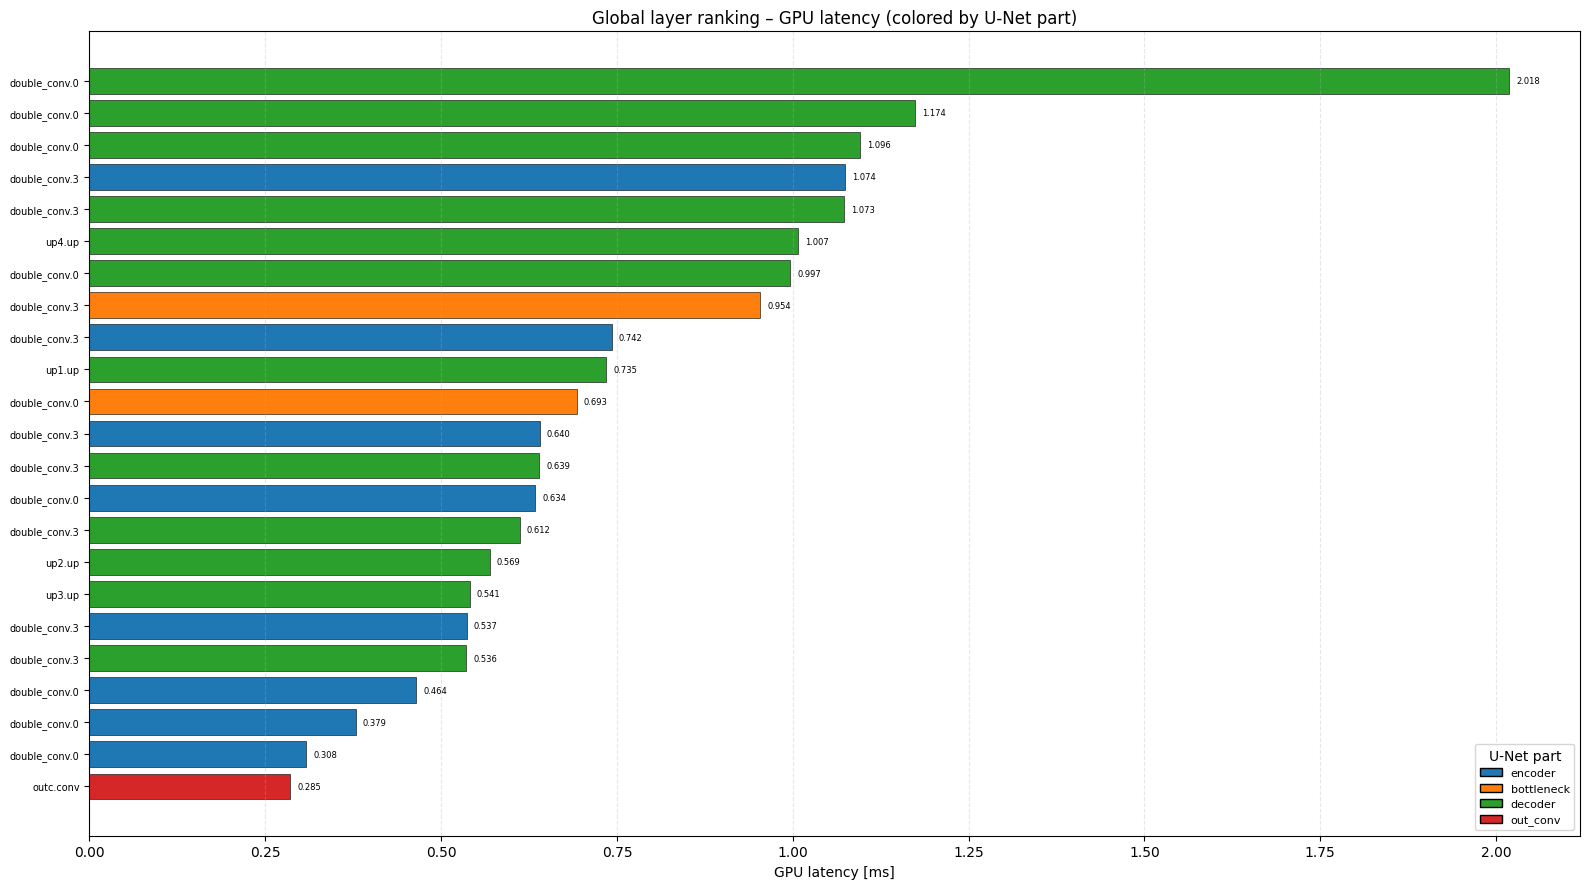

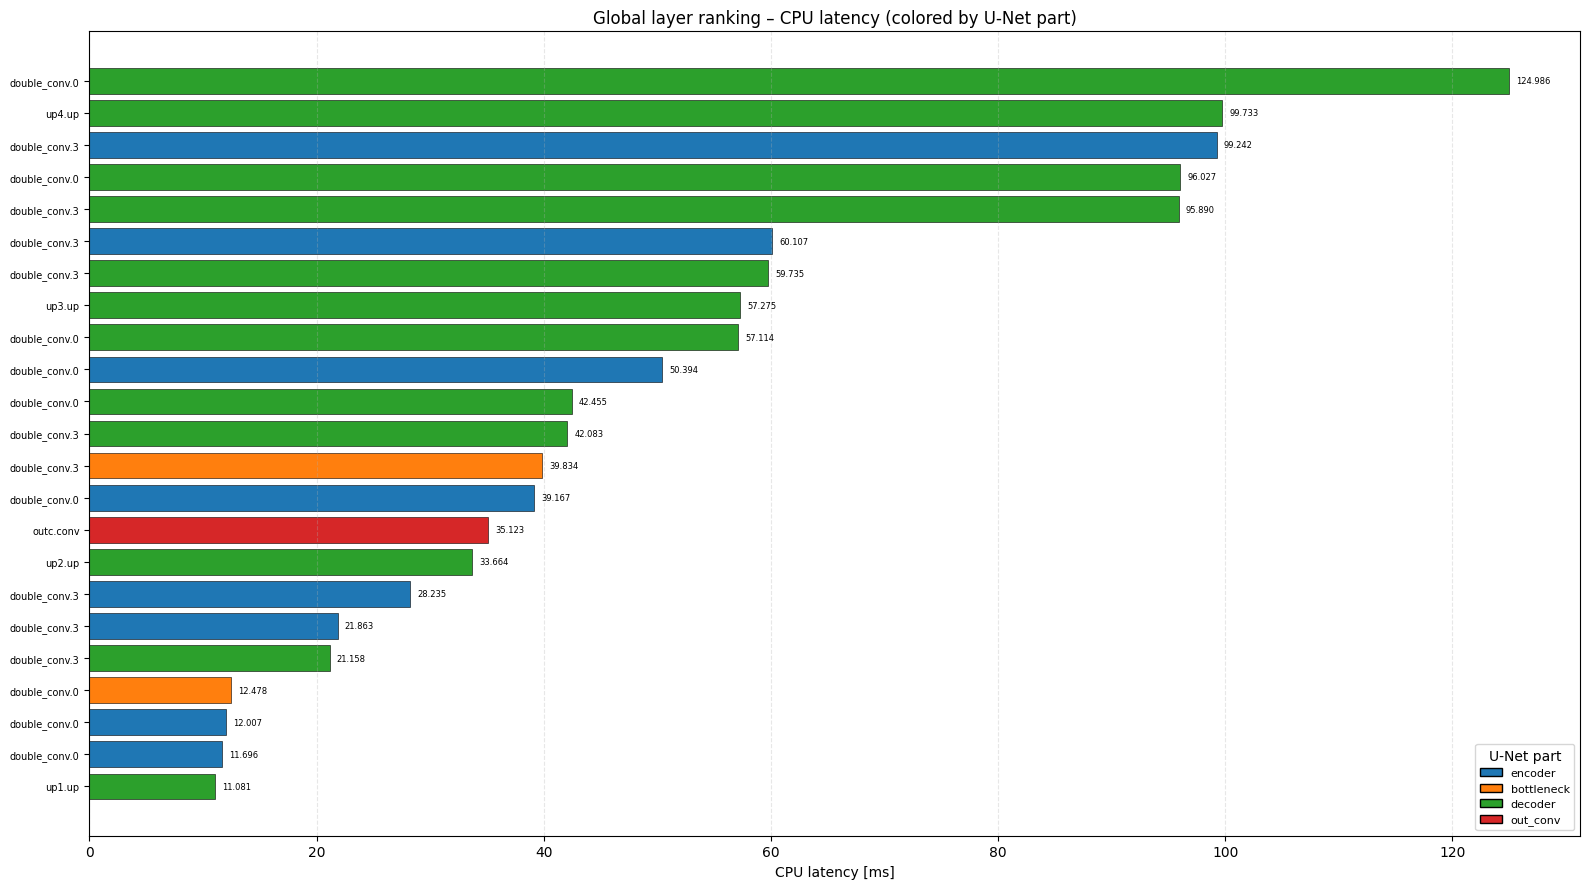

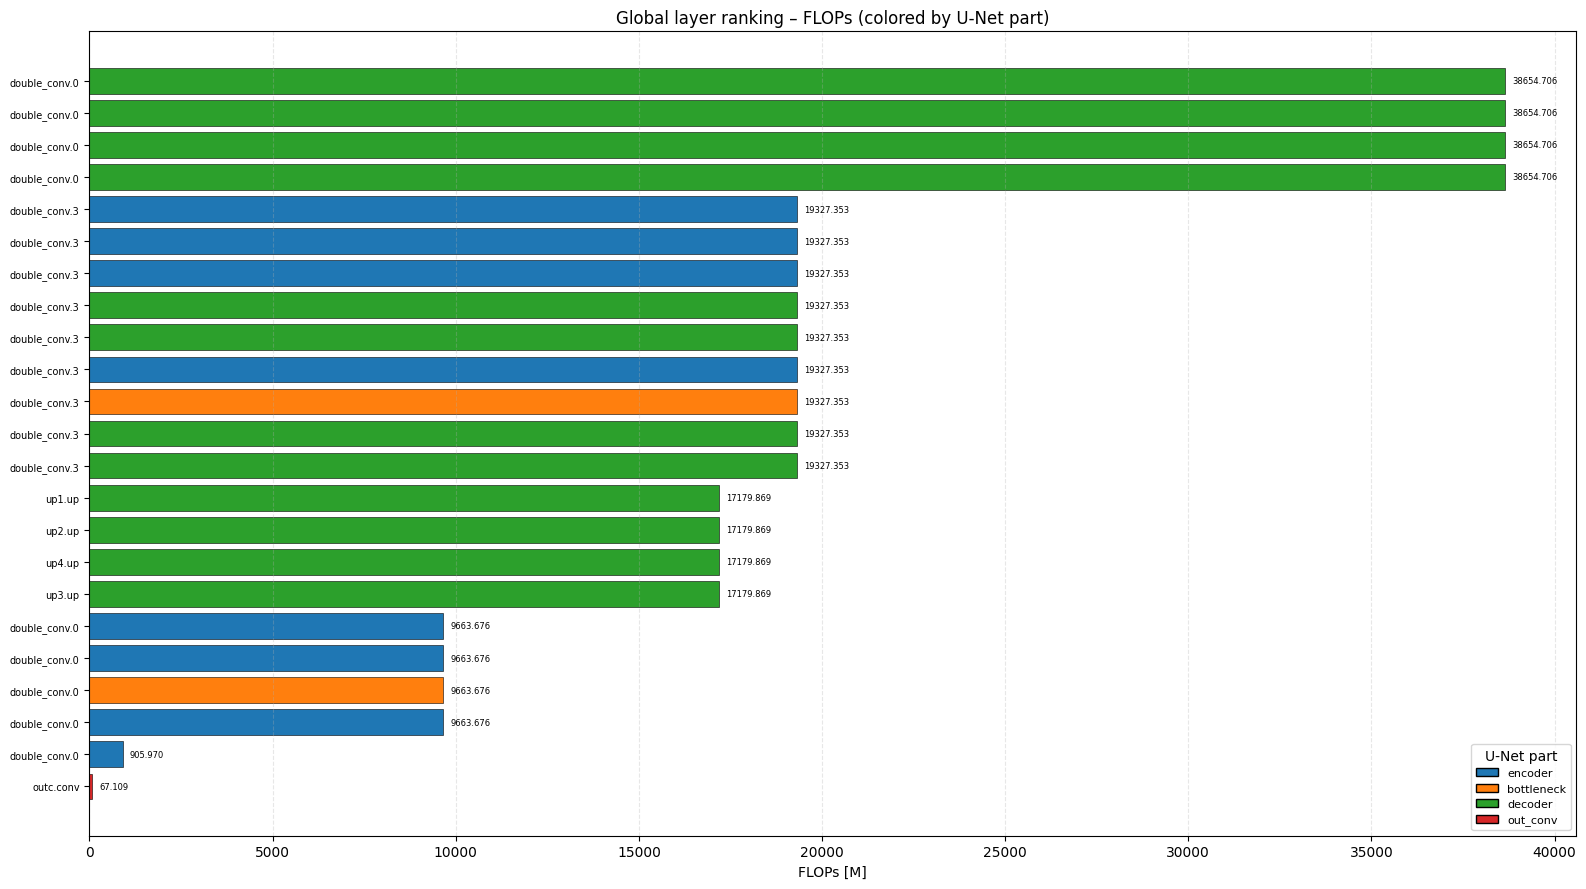

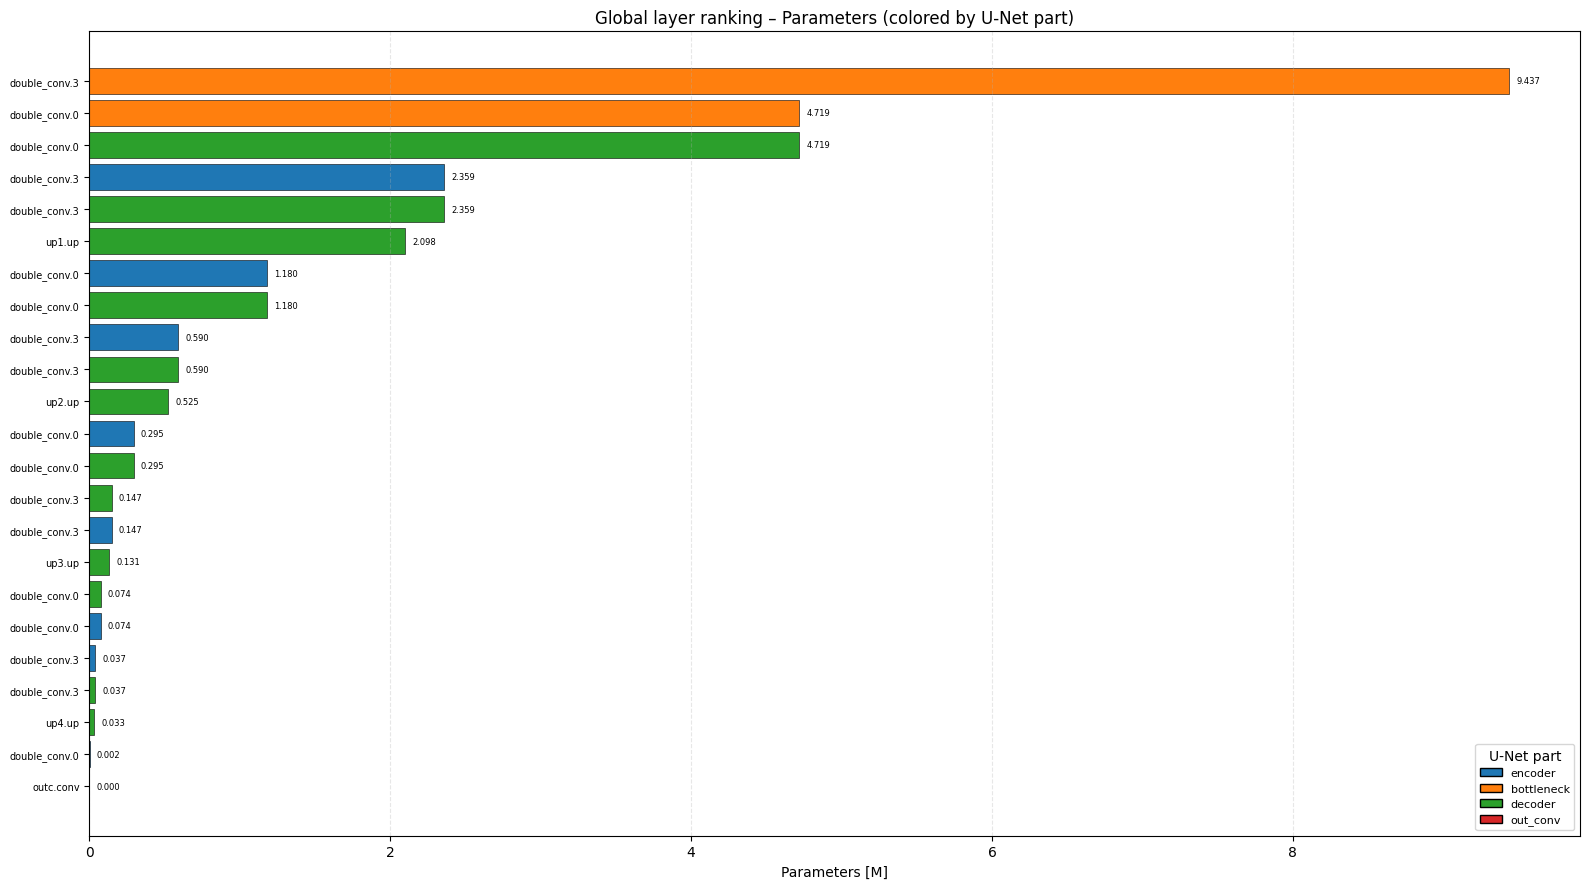

In [10]:
PART_COLORS = {
    'encoder'    : 'tab:blue',
    'bottleneck' : 'tab:orange',
    'decoder'    : 'tab:green',
    'out_conv'   : 'tab:red',
    'unknown'    : 'gray',
}


def plot_global_ranking(df_sorted: pd.DataFrame,
                        value_col: str,
                        ylabel: str,
                        title: str,
                        part_colors: dict,
                        top_n: int = None,
                        figsize=(16, 5)):
    """
    Horizontal bar chart, one bar per layer, ordered by value_col (desc).
    Bars are colored by U-Net part.  Legend shows part membership.
    top_n: if set, show only the top-N most expensive layers.
    """
    df = df_sorted.copy()
    if top_n is not None:
        df = df.head(top_n)

    # Short labels: last two path components
    labels = [
        '.'.join(n.split('.')[-2:]) if n.count('.') >= 2 else n
        for n in df['layer_name']
    ]
    colors = [part_colors.get(p, 'gray') for p in df['part']]
    values = df[value_col].values

    fig, ax = plt.subplots(figsize=figsize)
    y_pos = np.arange(len(labels))
    bars = ax.barh(y_pos, values, color=colors, edgecolor='black', linewidth=0.4)

    for bar, v in zip(bars, values):
        ax.text(bar.get_width() + values.max() * 0.005, bar.get_y() + bar.get_height() / 2,
                f'{v:.3f}', va='center', fontsize=6)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=7)
    ax.invert_yaxis()  # rank-1 on top
    ax.set_xlabel(ylabel)
    ax.set_title(title)
    ax.grid(axis='x', linestyle='--', alpha=0.3)

    # Legend
    from matplotlib.patches import Patch
    legend_handles = [
        Patch(facecolor=c, edgecolor='black', label=p)
        for p, c in part_colors.items()
        if p in df['part'].values
    ]
    ax.legend(handles=legend_handles, loc='lower right', fontsize=8, title='U-Net part')

    plt.tight_layout()
    plt.show()


# ── GPU Latency ranking ───────────────────────────────────────────────────
plot_global_ranking(
    df_ranked_gpu, 'time_gpu_ms', 'GPU latency [ms]',
    'Global layer ranking – GPU latency (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

# ── CPU Latency ranking ───────────────────────────────────────────────────
df_ranked_cpu = df_layers.sort_values('time_cpu_ms', ascending=False).reset_index(drop=True)
plot_global_ranking(
    df_ranked_cpu, 'time_cpu_ms', 'CPU latency [ms]',
    'Global layer ranking – CPU latency (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

# ── FLOPs ranking ────────────────────────────────────────────────────────
plot_global_ranking(
    df_ranked_flops, 'flops_M', 'FLOPs [M]',
    'Global layer ranking – FLOPs (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

# ── Parameters ranking ───────────────────────────────────────────────────
plot_global_ranking(
    df_ranked_params, 'params_M', 'Parameters [M]',
    'Global layer ranking – Parameters (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

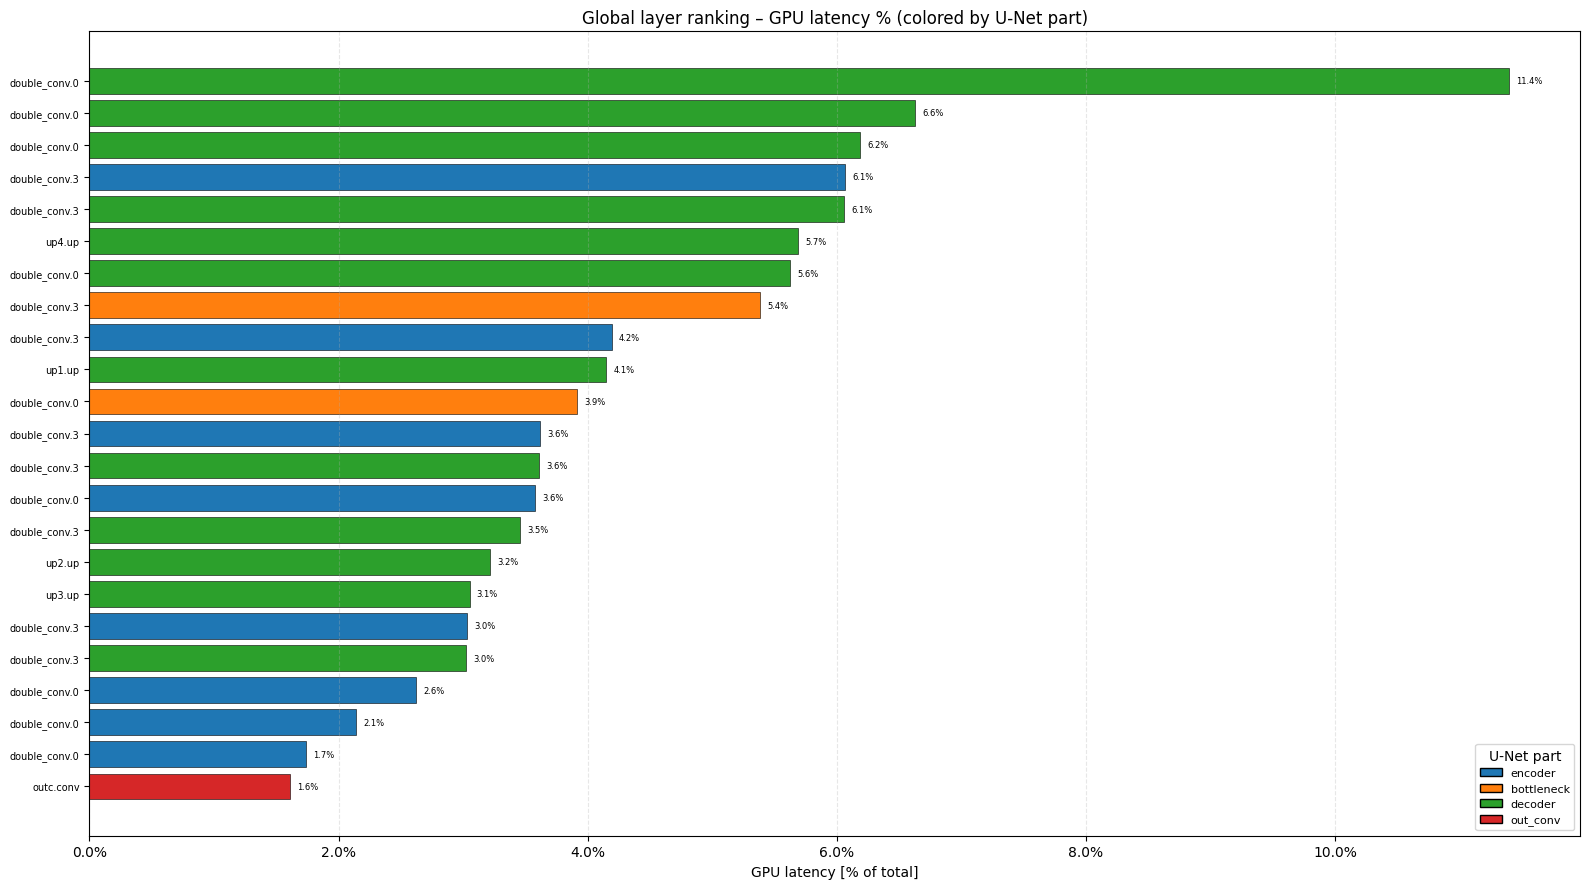

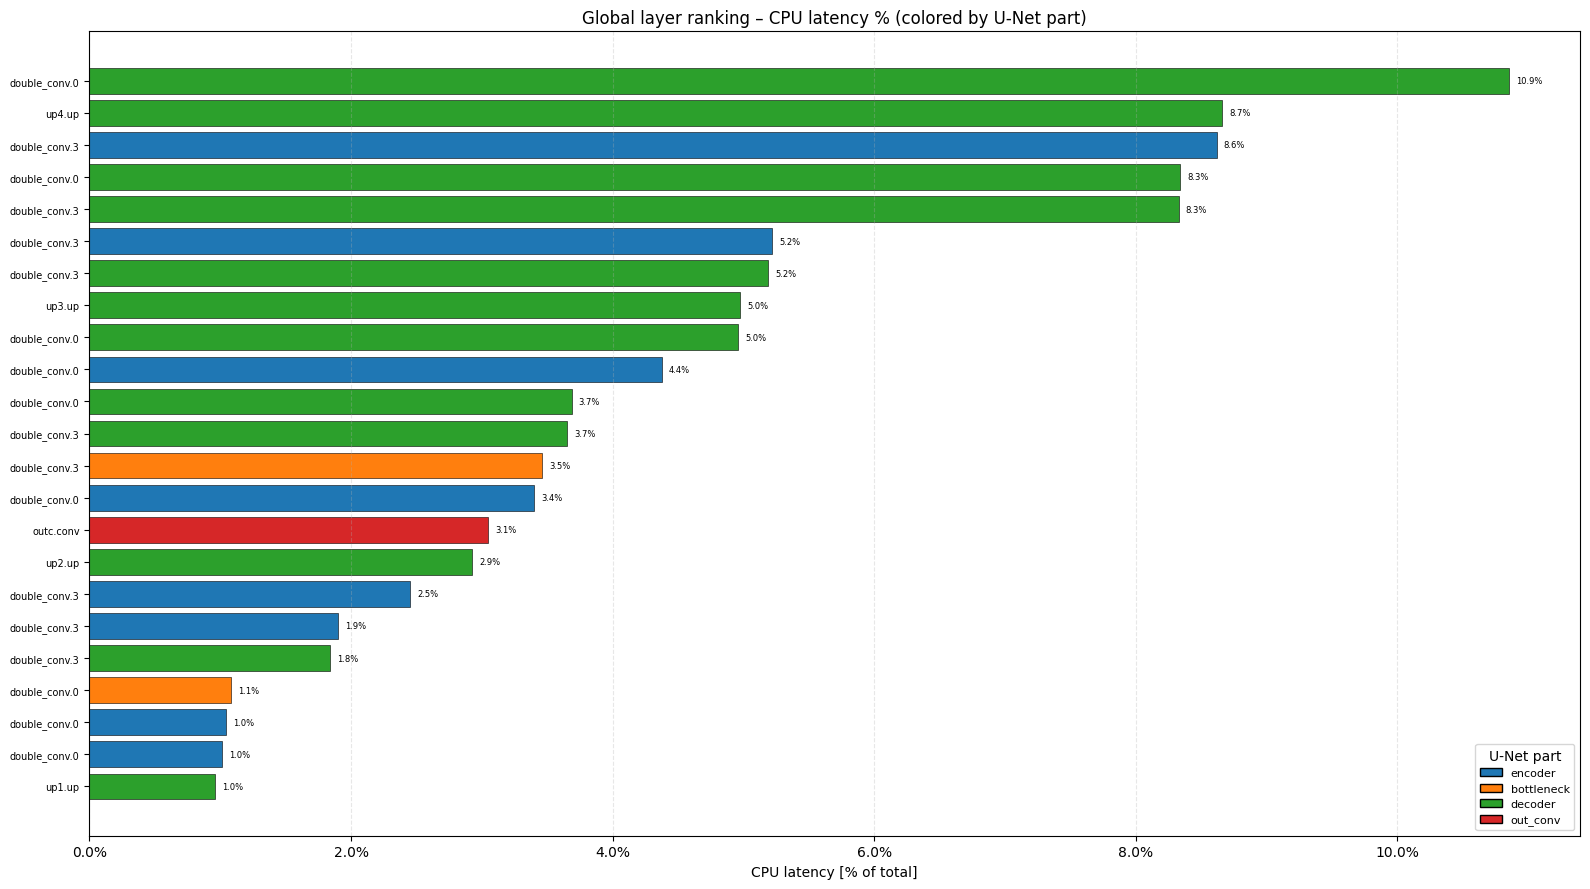

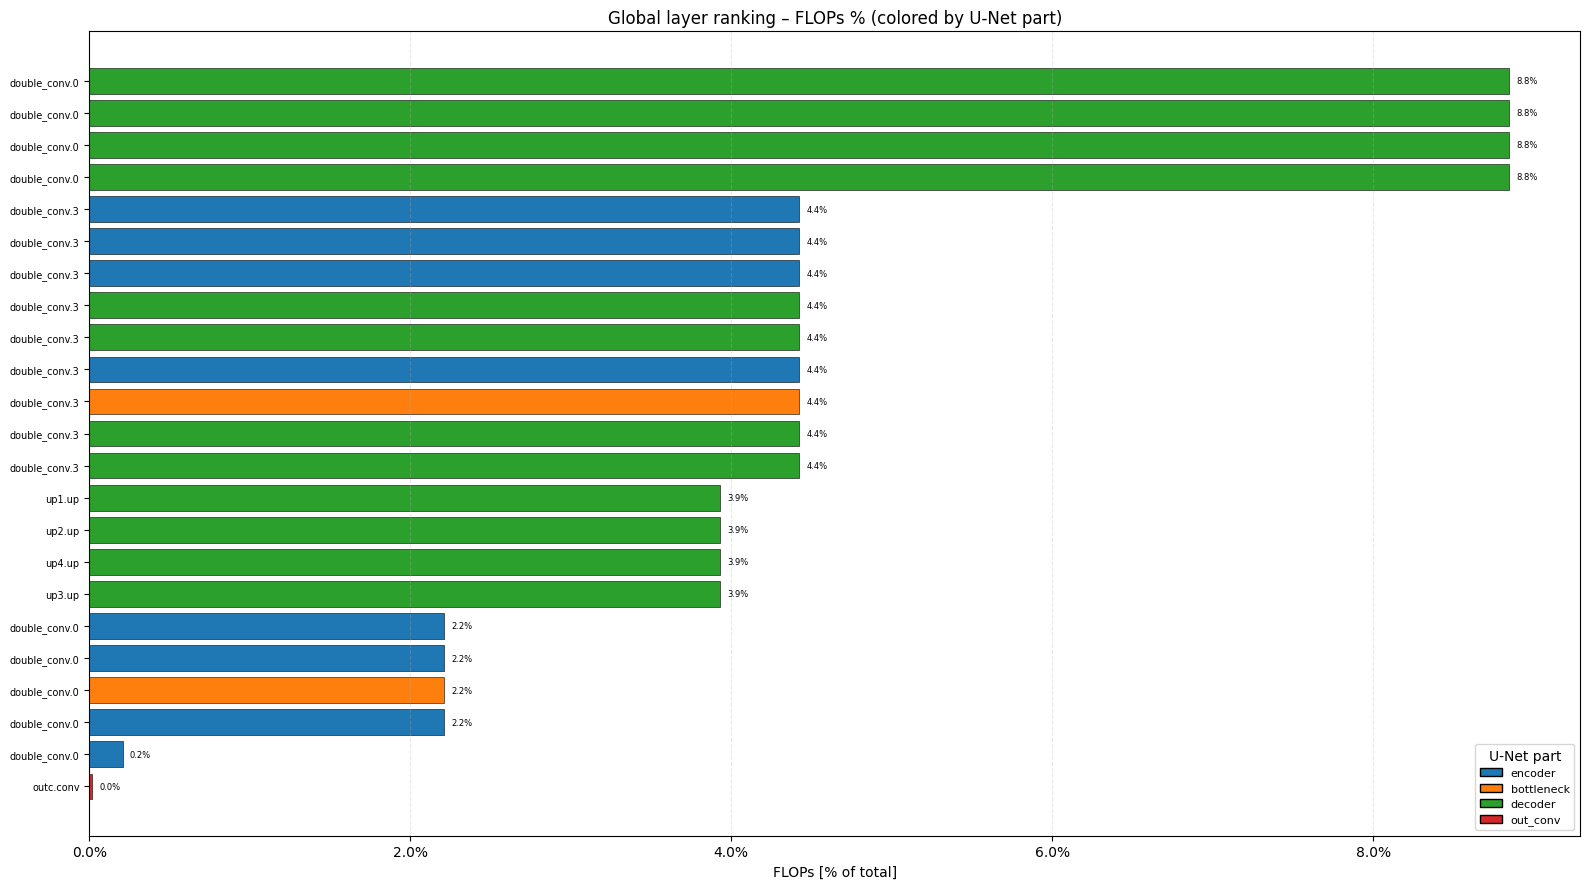

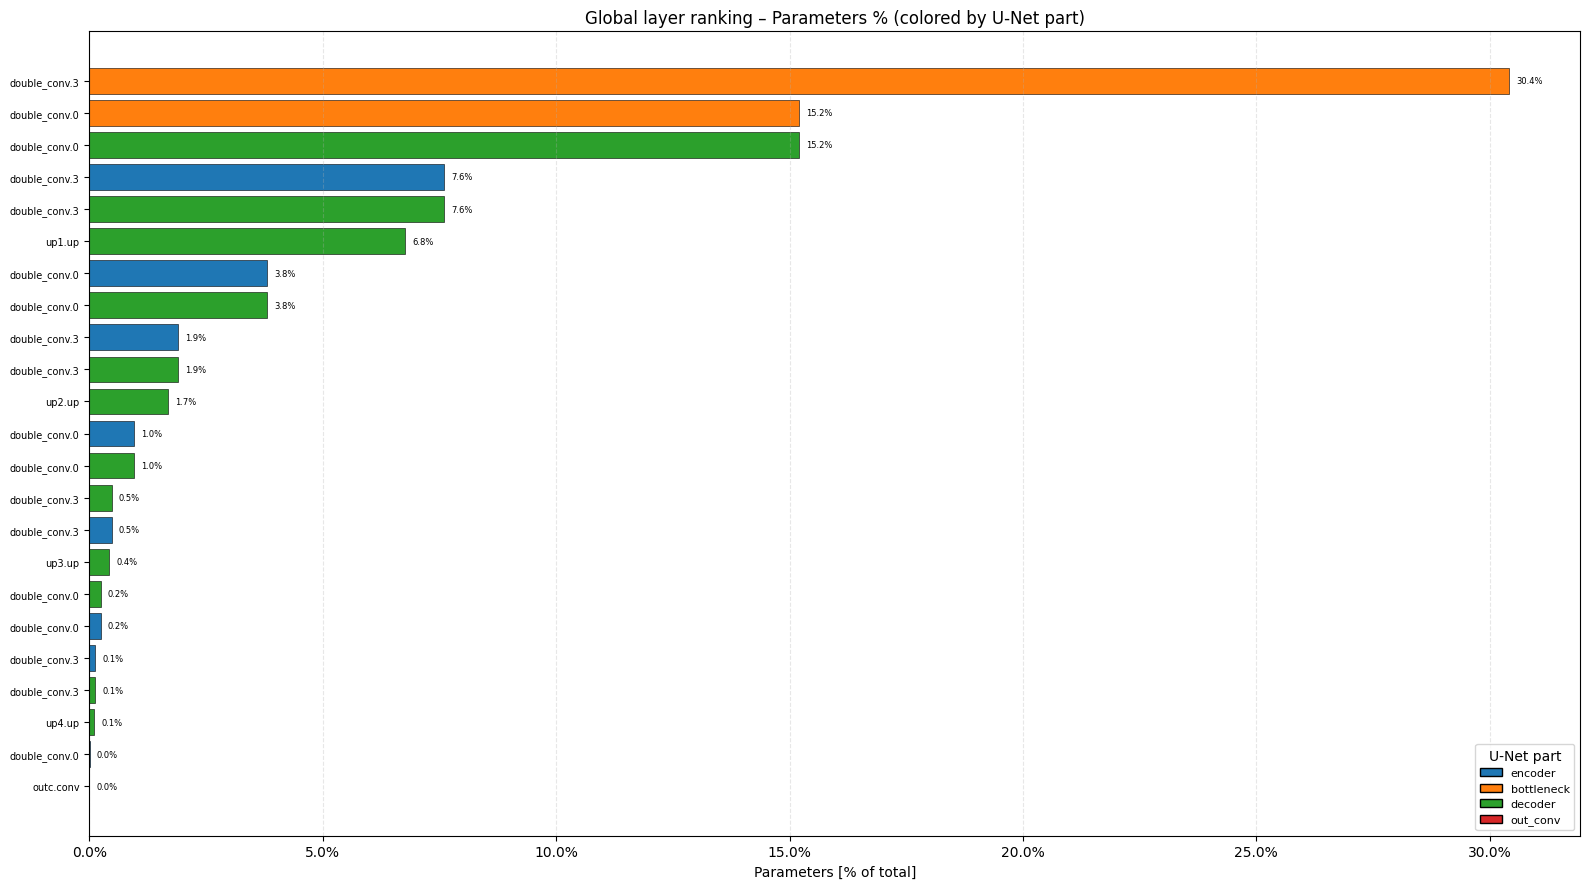

In [11]:
def plot_global_ranking_pct(df_sorted: pd.DataFrame,
                             value_col: str,
                             ylabel: str,
                             title: str,
                             part_colors: dict,
                             top_n: int = None,
                             figsize=(16, 5)):
    """
    Same as plot_global_ranking but values are shown as % of total.
    """
    df = df_sorted.copy()
    if top_n is not None:
        df = df.head(top_n)

    total = df[value_col].sum()
    df['_pct'] = df[value_col] / total * 100

    labels = [
        '.'.join(n.split('.')[-2:]) if n.count('.') >= 2 else n
        for n in df['layer_name']
    ]
    colors  = [part_colors.get(p, 'gray') for p in df['part']]
    values  = df['_pct'].values

    fig, ax = plt.subplots(figsize=figsize)
    y_pos = np.arange(len(labels))
    bars = ax.barh(y_pos, values, color=colors, edgecolor='black', linewidth=0.4)

    for bar, v in zip(bars, values):
        ax.text(bar.get_width() + values.max() * 0.005,
                bar.get_y() + bar.get_height() / 2,
                f'{v:.1f}%', va='center', fontsize=6)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=7)
    ax.invert_yaxis()
    ax.set_xlabel(ylabel)
    ax.set_title(title)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1f}%'))
    ax.grid(axis='x', linestyle='--', alpha=0.3)

    from matplotlib.patches import Patch
    legend_handles = [
        Patch(facecolor=c, edgecolor='black', label=p)
        for p, c in part_colors.items()
        if p in df['part'].values
    ]
    ax.legend(handles=legend_handles, loc='lower right', fontsize=8, title='U-Net part')

    plt.tight_layout()
    plt.show()


# ── GPU Latency % ────────────────────────────────────────────────────────
plot_global_ranking_pct(
    df_ranked_gpu, 'time_gpu_ms', 'GPU latency [% of total]',
    'Global layer ranking – GPU latency % (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

# ── CPU Latency % ────────────────────────────────────────────────────────
plot_global_ranking_pct(
    df_ranked_cpu, 'time_cpu_ms', 'CPU latency [% of total]',
    'Global layer ranking – CPU latency % (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

# ── FLOPs % ──────────────────────────────────────────────────────────────
plot_global_ranking_pct(
    df_ranked_flops, 'flops_M', 'FLOPs [% of total]',
    'Global layer ranking – FLOPs % (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

# ── Parameters % ─────────────────────────────────────────────────────────
plot_global_ranking_pct(
    df_ranked_params, 'params_M', 'Parameters [% of total]',
    'Global layer ranking – Parameters % (colored by U-Net part)',
    PART_COLORS, figsize=(16, 9)
)

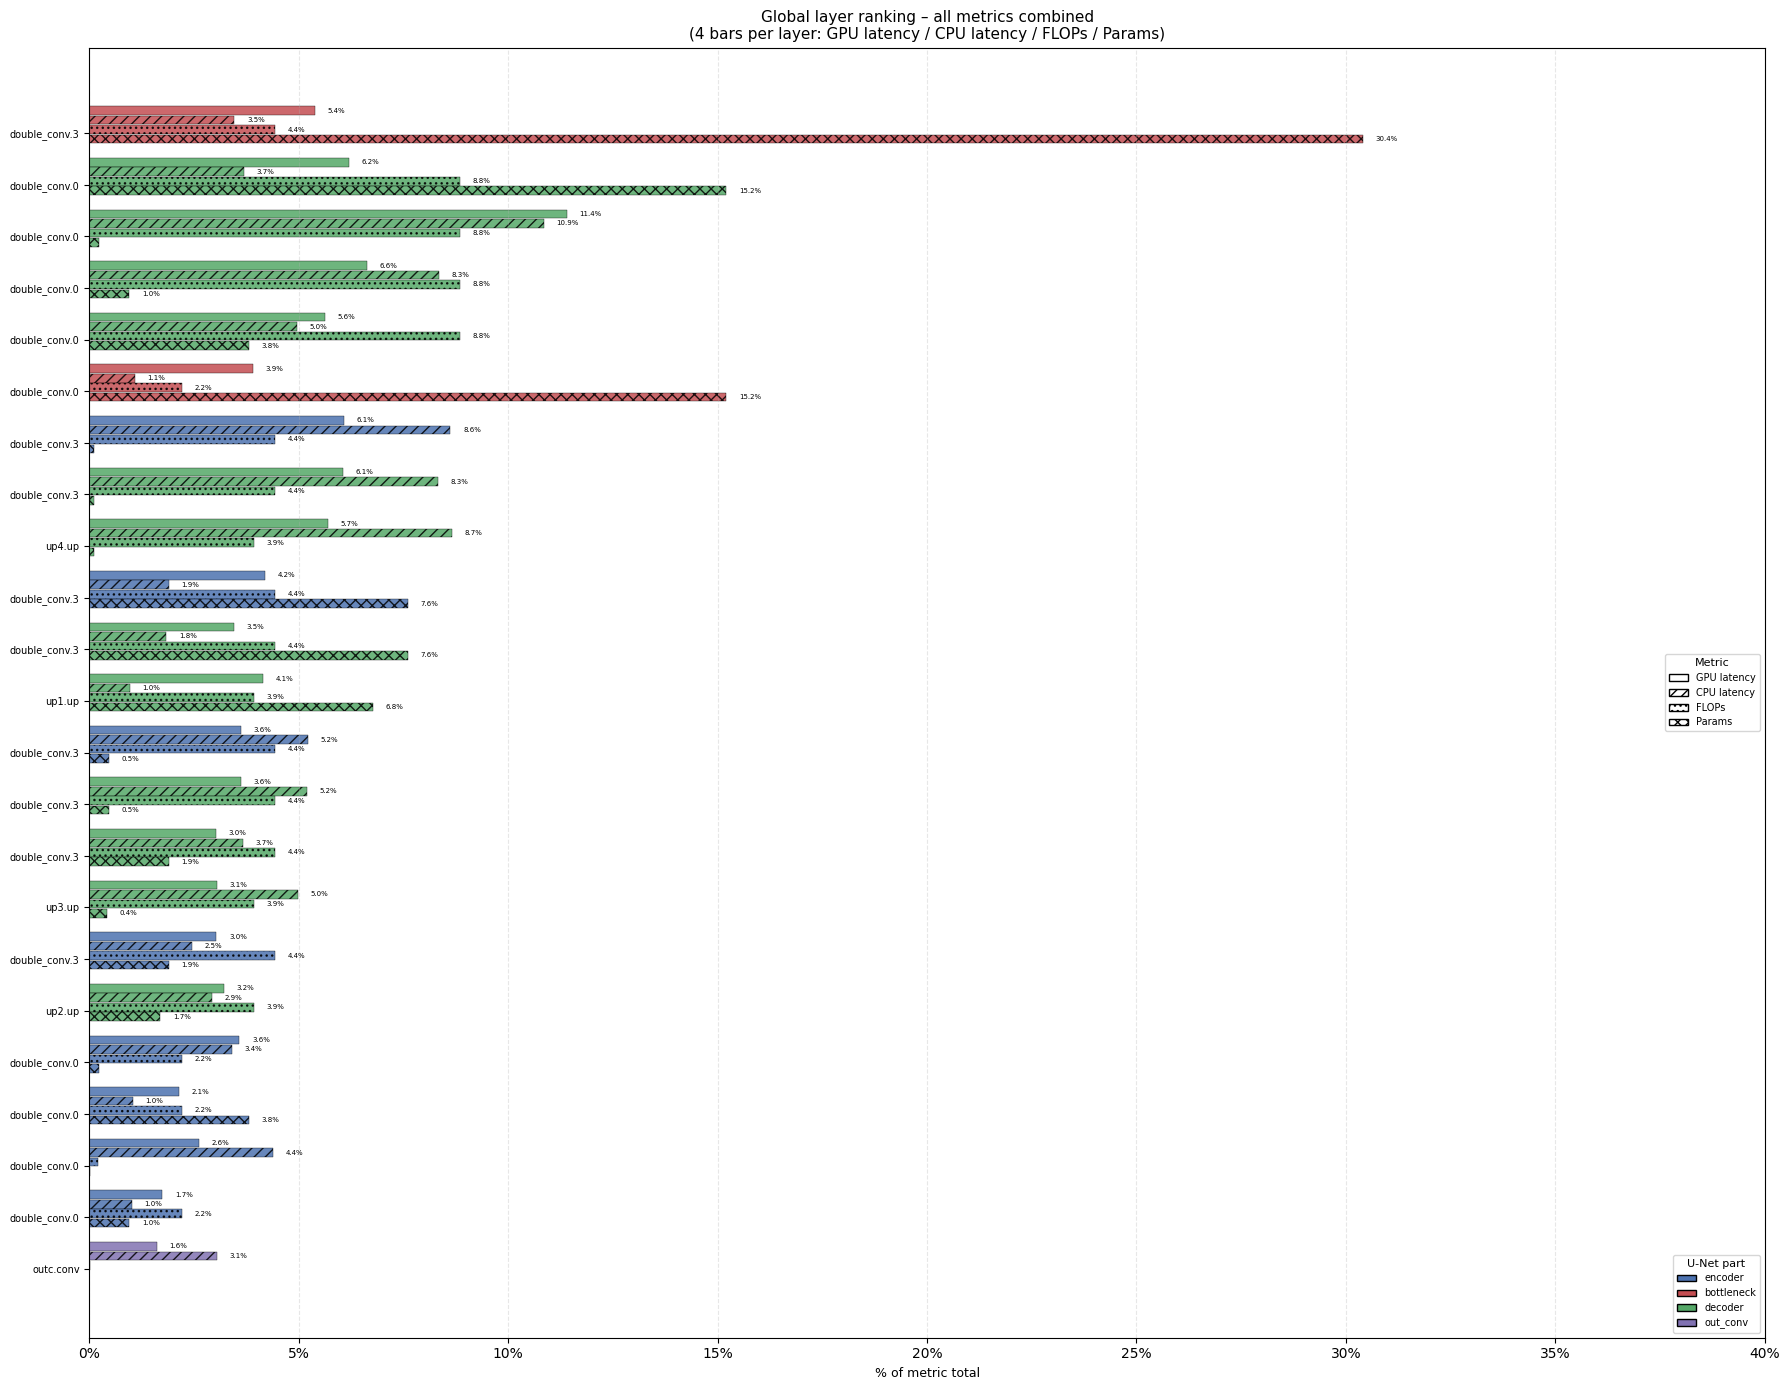

In [25]:
def plot_combined_ranking(dfs: dict,
                           value_cols: dict,
                           part_colors: dict,
                           top_n: int = None,
                           figsize=(18, 12)):
    """
    Combined horizontal bar chart with 4 slim bars per layer.
    Each metric is normalized to % of its own total so all 4 share the same x-axis (0–100%).

    Parameters
    ----------
    dfs        : dict  metric_name -> DataFrame (pre-sorted)
    value_cols : dict  metric_name -> column name in that DataFrame
    part_colors: dict  part -> color  (same PART_COLORS dict)
    top_n      : int   restrict to top-N layers by average rank across metrics
    """
    import matplotlib.patches as mpatches

    METRICS = list(dfs.keys())   # preserves insertion order

    # ── 1. Collect all layer names that appear in every metric ────────────
    all_layers = None
    for name, df in dfs.items():
        layers = set(df['layer_name'].tolist())
        all_layers = layers if all_layers is None else all_layers & layers
    # Sort by average normalised rank across the four metrics
    rank_sum = {}
    for layer in all_layers:
        s = 0
        for name, df in dfs.items():
            col = value_cols[name]
            idx = df.index[df['layer_name'] == layer]
            s  += df.loc[idx[0], col] / df[col].sum() if len(idx) else 0
        rank_sum[layer] = s
    ordered_layers = sorted(all_layers, key=lambda l: rank_sum[l], reverse=True)
    if top_n:
        ordered_layers = ordered_layers[:top_n]

    N = len(ordered_layers)

    # ── 2. Build pct lookup  {metric: {layer: pct}} ──────────────────────
    pct = {}
    for name, df in dfs.items():
        col   = value_cols[name]
        total = df[col].sum()
        pct[name] = {
            row['layer_name']: row[col] / total * 100
            for _, row in df.iterrows()
        }

    # Part lookup (use the first df that has the layer)
    part_lookup = {}
    for name, df in dfs.items():
        for _, row in df.iterrows():
            part_lookup.setdefault(row['layer_name'], row['part'])

    # ── 3. Layout ─────────────────────────────────────────────────────────
    n_metrics   = len(METRICS)
    bar_h       = 0.25         # height of each slim bar
    group_h     = 1.5           # total height reserved per layer
    gap         = (group_h - n_metrics * bar_h) / (n_metrics + 1)  # spacing inside group

    fig, ax = plt.subplots(figsize=figsize)

    # Hatches to distinguish metrics even in greyscale
    HATCHES = ['', '///', '...', 'xxx']

    metric_patch = []   # for legend

    for m_idx, metric_name in enumerate(METRICS):
        hatch = HATCHES[m_idx % len(HATCHES)]
        for l_idx, layer in enumerate(ordered_layers):
            val   = pct[metric_name].get(layer, 0)
            part  = part_lookup.get(layer, 'unknown')
            color = part_colors.get(part, 'gray')

            # y centre of this bar inside its group
            group_top = -(l_idx * group_h)          # groups grow downward
            bar_y     = group_top - gap - m_idx * (bar_h + gap / n_metrics)

            ax.barh(bar_y, val,
                    height=bar_h,
                    color=color,
                    hatch=hatch,
                    edgecolor='black',
                    linewidth=0.3,
                    alpha=0.85)

            if val > 0.3:   # skip tiny labels
                ax.text(val + 0.3, bar_y,
                        f'{val:.1f}%', va='center', fontsize=5)

        # Collect legend entry per metric
        metric_patch.append(
            mpatches.Patch(facecolor='white', edgecolor='black',
                           hatch=hatch, label=metric_name)
        )

    # ── 4. Y-axis: one tick per layer group ───────────────────────────────
    group_centers = [-(i * group_h + group_h / 2) for i in range(N)]
    short_labels  = [
        '.'.join(l.split('.')[-2:]) if l.count('.') >= 2 else l
        for l in ordered_layers
    ]
    ax.set_yticks(group_centers)
    ax.set_yticklabels(short_labels, fontsize=7)

    # ── 5. Axes formatting ────────────────────────────────────────────────
    ax.set_xlabel('% of metric total', fontsize=9)
    ax.set_title('Global layer ranking – all metrics combined\n'
                 '(4 bars per layer: GPU latency / CPU latency / FLOPs / Params)',
                 fontsize=11)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))
    ax.set_xlim(0, 40)
    ax.grid(axis='x', linestyle='--', alpha=0.3)

    # ── 6. Two-part legend: parts (colors) + metrics (hatches) ───────────
    part_patches = [
        mpatches.Patch(facecolor=c, edgecolor='black', label=p)
        for p, c in part_colors.items()
        if p in part_lookup.values()
    ]
    legend1 = ax.legend(handles=part_patches,
                        loc='lower right', fontsize=7,
                        title='U-Net part', title_fontsize=8)
    ax.add_artist(legend1)
    ax.legend(handles=metric_patch,
              loc='center right', fontsize=7,
              title='Metric', title_fontsize=8)

    plt.tight_layout()
    plt.show()


# ── Call it ───────────────────────────────────────────────────────────────
plot_combined_ranking(
    dfs={
        'GPU latency' : df_ranked_gpu,
        'CPU latency' : df_ranked_cpu,
        'FLOPs'       : df_ranked_flops,
        'Params'      : df_ranked_params,
    },
    value_cols={
        'GPU latency' : 'time_gpu_ms',
        'CPU latency' : 'time_cpu_ms',
        'FLOPs'       : 'flops_M',
        'Params'      : 'params_M',
    },
    part_colors=PART_COLORS,
    figsize=(18, 14)
)

### 2.7  Within-part ranking (secondary reference)

Same layers, but now the ranking is **within each part** so you can see
which layers are cheapest/most expensive *relative to their neighbours*.
The global rank is still shown for cross-part comparison.

In [13]:
# ── Within-part rank columns ────────────────────────────────────────────
for metric in ('params_M', 'flops_M', 'time_gpu_ms', 'time_cpu_ms'):
    df_layers[f'part_rank_{metric}'] = (
        df_layers.groupby('part')[metric]
        .rank(ascending=False, method='min')
        .astype(int)
    )

# ── Print within-part table for each part ──────────────────────────────
detail_cols = [
    'part_rank_time_gpu_ms', 'rank_time_gpu_ms',
    'layer_name', 'type', 'in_ch', 'out_ch', 'kernel',
    'params_M', 'flops_M', 'time_gpu_ms'
]

for part in ('encoder', 'bottleneck', 'decoder', 'out_conv'):
    subset = (
        df_layers[df_layers['part'] == part]
        .sort_values('time_gpu_ms', ascending=False)
        .reset_index(drop=True)
    )
    if subset.empty:
        continue
    print(f'\n=== Within-part ranking: {part.upper()} ===')
    display(subset[detail_cols])


=== Within-part ranking: ENCODER ===


,part_rank_time_gpu_ms,rank_time_gpu_ms,layer_name,type,in_ch,out_ch,kernel,params_M,flops_M,time_gpu_ms
0,1,4,inc.double_conv.3,Conv2d,64,64,"(3, 3)",0.036864,19327.352832,1.074222
1,2,9,down3.maxpool_conv.1.double_conv.3,Conv2d,512,512,"(3, 3)",2.359296,19327.352832,0.742239
2,3,12,down1.maxpool_conv.1.double_conv.3,Conv2d,128,128,"(3, 3)",0.147456,19327.352832,0.640229
3,4,14,down1.maxpool_conv.1.double_conv.0,Conv2d,64,128,"(3, 3)",0.073728,9663.676416,0.633846
4,5,18,down2.maxpool_conv.1.double_conv.3,Conv2d,256,256,"(3, 3)",0.589824,19327.352832,0.536512
5,6,20,inc.double_conv.0,Conv2d,3,64,"(3, 3)",0.001728,905.969664,0.464365
6,7,21,down3.maxpool_conv.1.double_conv.0,Conv2d,256,512,"(3, 3)",1.179648,9663.676416,0.378688
7,8,22,down2.maxpool_conv.1.double_conv.0,Conv2d,128,256,"(3, 3)",0.294912,9663.676416,0.308349



=== Within-part ranking: BOTTLENECK ===


,part_rank_time_gpu_ms,rank_time_gpu_ms,layer_name,type,in_ch,out_ch,kernel,params_M,flops_M,time_gpu_ms
0,1,8,down4.maxpool_conv.1.double_conv.3,Conv2d,1024,1024,"(3, 3)",9.437184,19327.352832,0.953627
1,2,11,down4.maxpool_conv.1.double_conv.0,Conv2d,512,1024,"(3, 3)",4.718592,9663.676416,0.692778



=== Within-part ranking: DECODER ===


,part_rank_time_gpu_ms,rank_time_gpu_ms,layer_name,type,in_ch,out_ch,kernel,params_M,flops_M,time_gpu_ms
0,1,1,up4.conv.double_conv.0,Conv2d,128,64,"(3, 3)",0.073728,38654.705664,2.018318
1,2,2,up3.conv.double_conv.0,Conv2d,256,128,"(3, 3)",0.294912,38654.705664,1.174148
2,3,3,up1.conv.double_conv.0,Conv2d,1024,512,"(3, 3)",4.718592,38654.705664,1.096184
3,4,5,up4.conv.double_conv.3,Conv2d,64,64,"(3, 3)",0.036864,19327.352832,1.073480
4,5,6,up4.up,ConvTranspose2d,128,64,"(2, 2)",0.032832,17179.869184,1.007473
5,6,7,up2.conv.double_conv.0,Conv2d,512,256,"(3, 3)",1.179648,38654.705664,0.996519
6,7,10,up1.up,ConvTranspose2d,1024,512,"(2, 2)",2.097664,17179.869184,0.734855
7,8,13,up3.conv.double_conv.3,Conv2d,128,128,"(3, 3)",0.147456,19327.352832,0.639261
8,9,15,up1.conv.double_conv.3,Conv2d,512,512,"(3, 3)",2.359296,19327.352832,0.611701
9,10,16,up2.up,ConvTranspose2d,512,256,"(2, 2)",0.524544,17179.869184,0.569122



=== Within-part ranking: OUT_CONV ===


,part_rank_time_gpu_ms,rank_time_gpu_ms,layer_name,type,in_ch,out_ch,kernel,params_M,flops_M,time_gpu_ms
0,1,23,outc.conv,Conv2d,64,2,"(1, 1)",0.00013,67.108864,0.285495


### 2.8  Within-part ranking – visual (GPU latency)

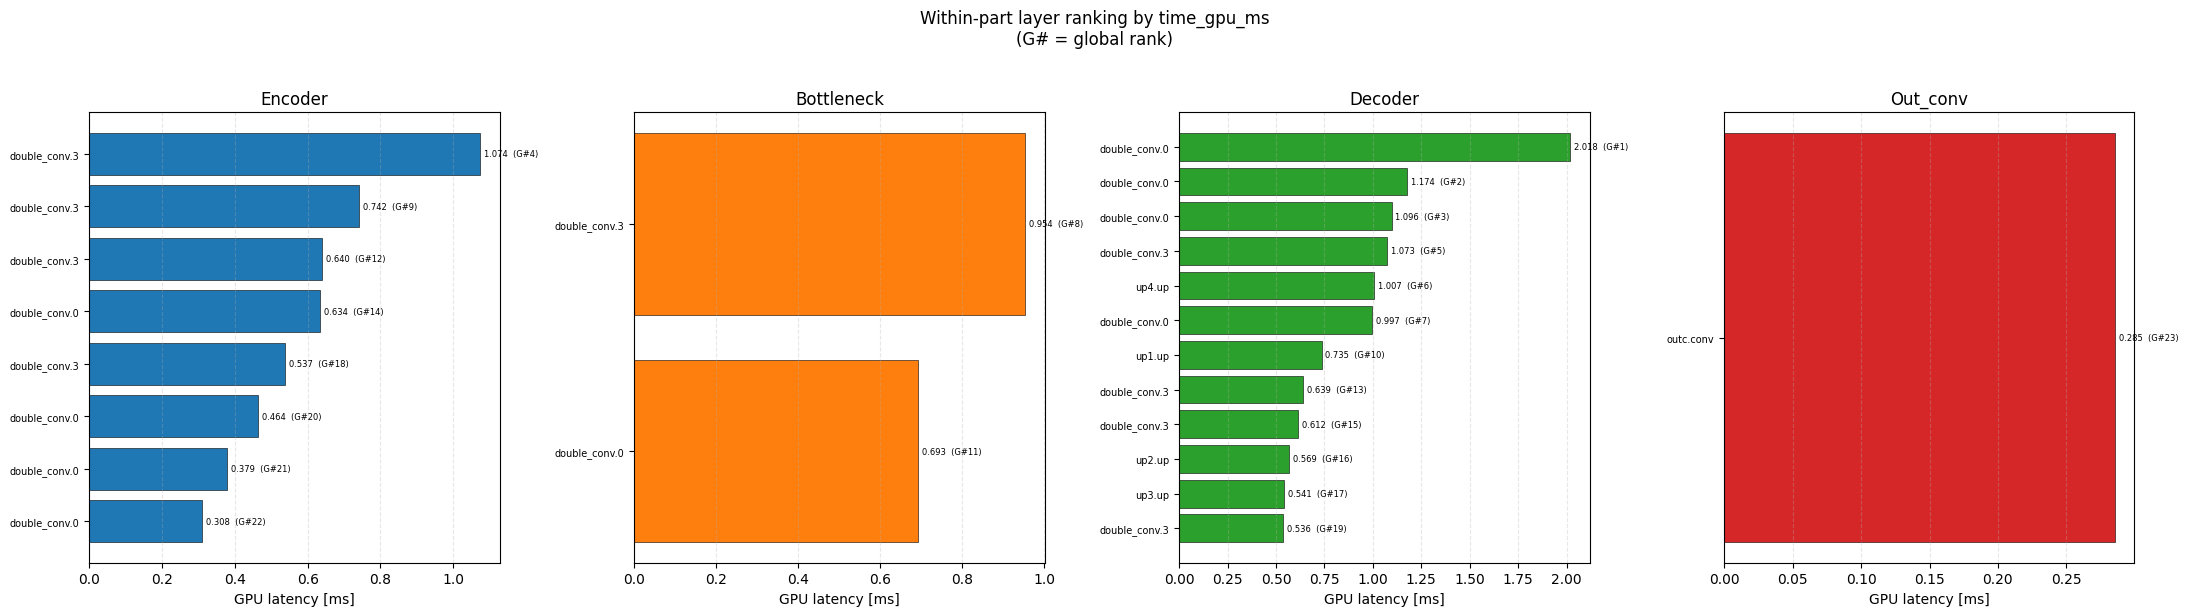

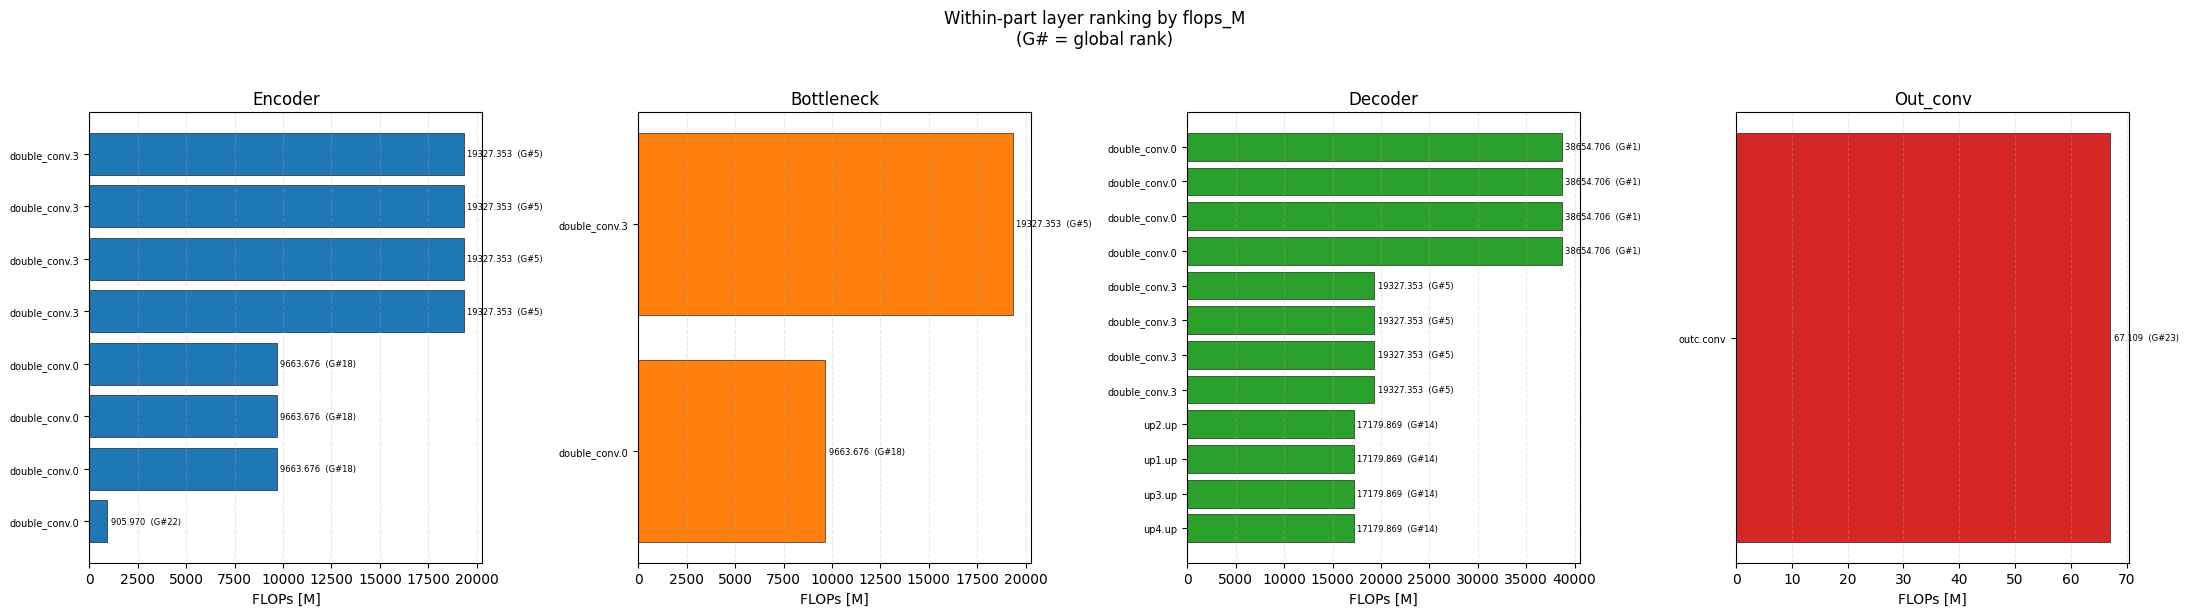

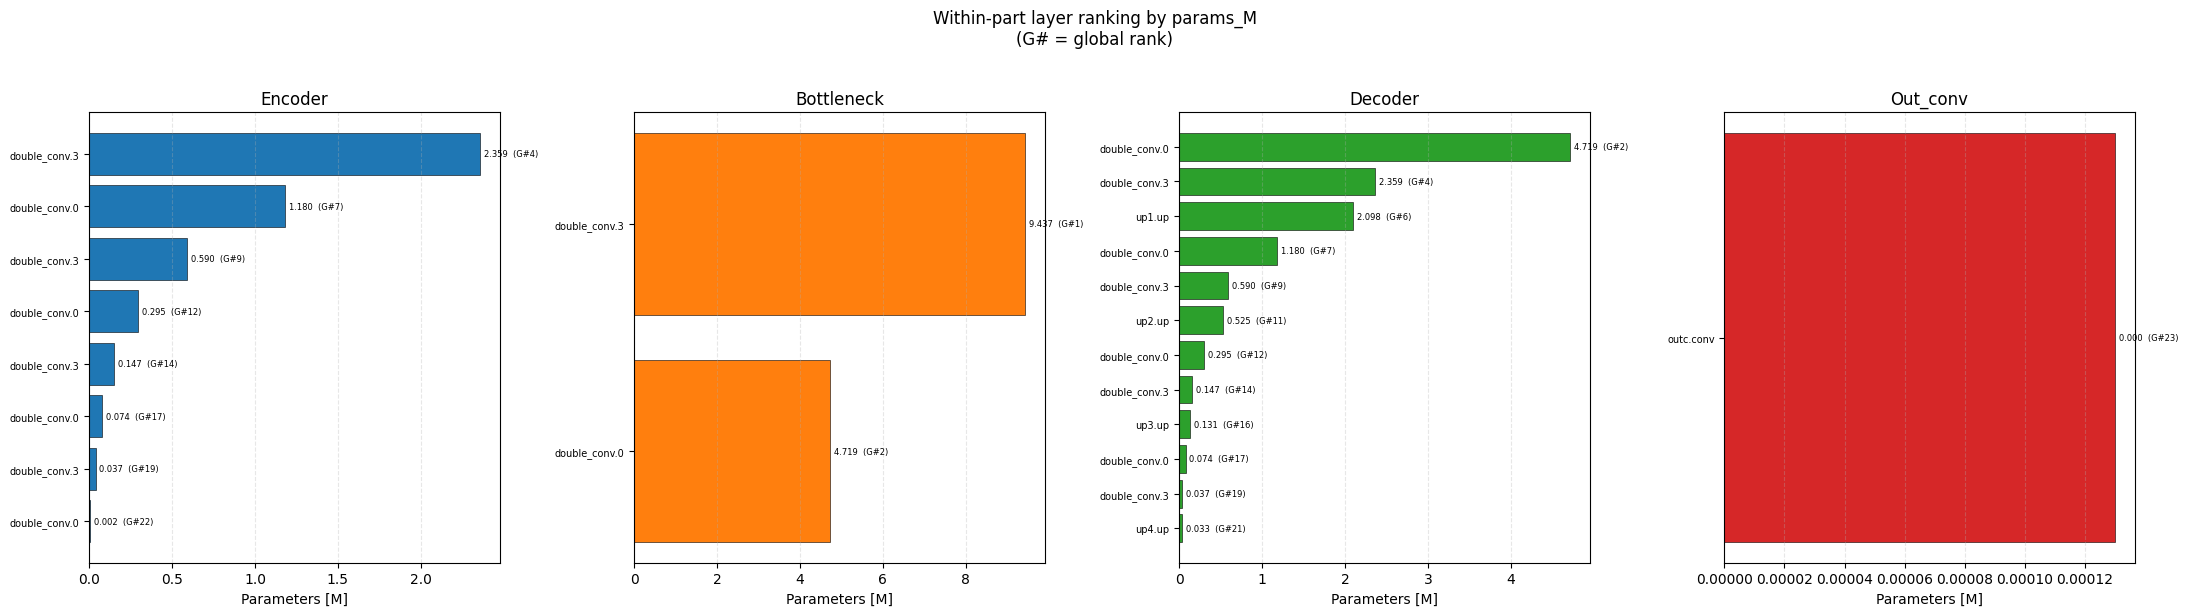

In [14]:
def plot_within_part_ranking(df_layers: pd.DataFrame,
                             value_col: str,
                             ylabel: str,
                             part_colors: dict,
                             figsize=(18, 5)):
    """
    One subplot per U-Net part.  Within each subplot layers are ranked
    descending by value_col.  Global rank shown in bar label.
    """
    parts = ['encoder', 'bottleneck', 'decoder', 'out_conv']
    parts = [p for p in parts if p in df_layers['part'].values]
    n = len(parts)

    fig, axes = plt.subplots(1, n, figsize=figsize, sharey=False)
    if n == 1:
        axes = [axes]

    global_rank_col = f'rank_{value_col}'

    for ax, part in zip(axes, parts):
        sub = (
            df_layers[df_layers['part'] == part]
            .sort_values(value_col, ascending=False)
            .reset_index(drop=True)
        )
        labels = [
            '.'.join(n.split('.')[-2:]) if n.count('.') >= 2 else n
            for n in sub['layer_name']
        ]
        values = sub[value_col].values
        g_ranks = sub[global_rank_col].values if global_rank_col in sub else None
        color   = part_colors.get(part, 'gray')

        y_pos = np.arange(len(labels))
        bars = ax.barh(y_pos, values, color=color, edgecolor='black', linewidth=0.4)

        for i, (bar, v) in enumerate(zip(bars, values)):
            label_str = f'{v:.3f}'
            if g_ranks is not None:
                label_str += f'  (G#{g_ranks[i]})'
            ax.text(bar.get_width() + values.max() * 0.01,
                    bar.get_y() + bar.get_height() / 2,
                    label_str, va='center', fontsize=6)

        ax.set_yticks(y_pos)
        ax.set_yticklabels(labels, fontsize=7)
        ax.invert_yaxis()
        ax.set_xlabel(ylabel)
        ax.set_title(part.capitalize())
        ax.grid(axis='x', linestyle='--', alpha=0.3)

    fig.suptitle(f'Within-part layer ranking by {value_col}\n(G# = global rank)', y=1.02)
    plt.tight_layout()
    plt.show()


plot_within_part_ranking(
    df_layers, 'time_gpu_ms', 'GPU latency [ms]', PART_COLORS, figsize=(22, 6)
)
plot_within_part_ranking(
    df_layers, 'flops_M', 'FLOPs [M]', PART_COLORS, figsize=(22, 6)
)
plot_within_part_ranking(
    df_layers, 'params_M', 'Parameters [M]', PART_COLORS, figsize=(22, 6)
)

### 2.9  Cumulative cost – top-K layers cover X% of total cost

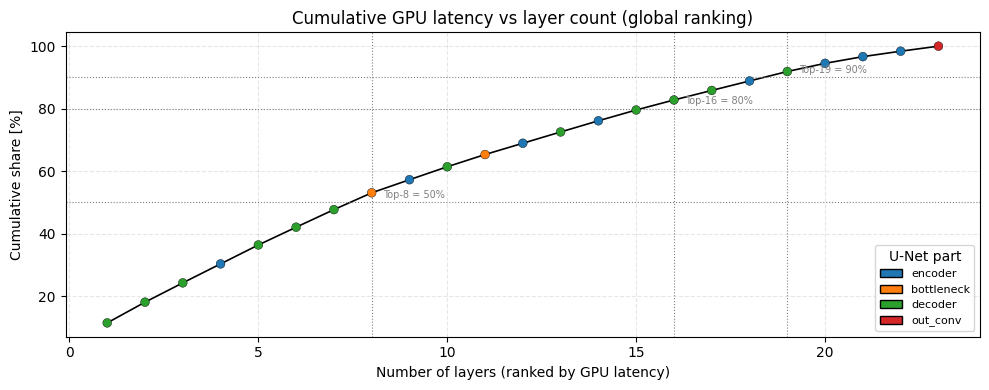

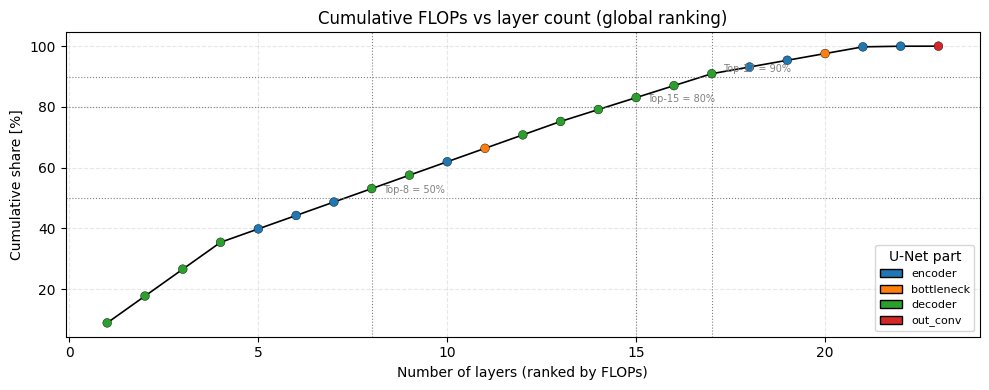

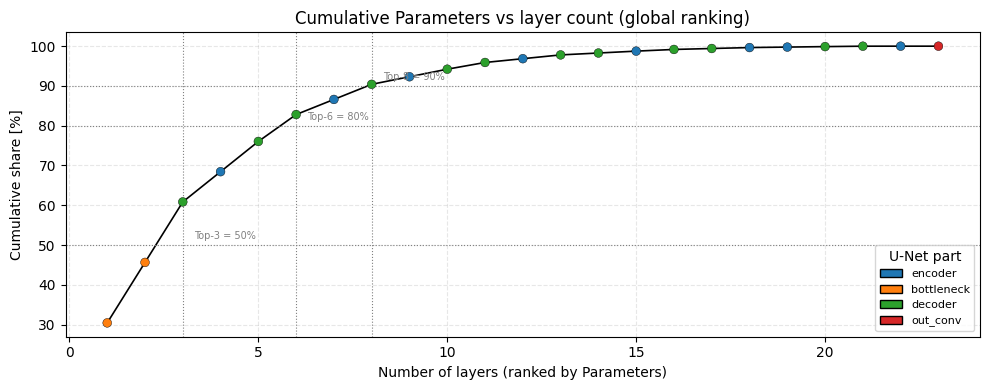

In [15]:
def plot_cumulative_cost(df_ranked: pd.DataFrame,
                         value_col: str,
                         xlabel: str,
                         part_colors: dict,
                         title: str,
                         figsize=(10, 4)):
    """
    Cumulative % of total cost as layers are added (most expensive first).
    Dots are colored by part.
    """
    vals   = df_ranked[value_col].values
    parts  = df_ranked['part'].values
    total  = vals.sum()
    cumsum = np.cumsum(vals) / (total + 1e-12) * 100.0
    colors = [part_colors.get(p, 'gray') for p in parts]

    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(np.arange(1, len(cumsum) + 1), cumsum, color='black', linewidth=1.2, zorder=2)
    ax.scatter(np.arange(1, len(cumsum) + 1), cumsum,
               c=colors, s=40, zorder=3, edgecolors='black', linewidths=0.3)

    for thr in (50, 80, 90):
        idx = np.searchsorted(cumsum, thr)
        if idx < len(cumsum):
            ax.axhline(thr, color='gray', linestyle=':', linewidth=0.8)
            ax.axvline(idx + 1, color='gray', linestyle=':', linewidth=0.8)
            ax.text(idx + 1.3, thr + 1.5,
                    f'Top-{idx+1} = {thr}%', fontsize=7, color='gray')

    ax.set_xlabel(xlabel)
    ax.set_ylabel('Cumulative share [%]')
    ax.set_title(title)
    ax.grid(linestyle='--', alpha=0.3)

    from matplotlib.patches import Patch
    legend_handles = [
        Patch(facecolor=c, edgecolor='black', label=p)
        for p, c in part_colors.items()
        if p in df_ranked['part'].values
    ]
    ax.legend(handles=legend_handles, fontsize=8, title='U-Net part')

    plt.tight_layout()
    plt.show()


plot_cumulative_cost(
    df_ranked_gpu, 'time_gpu_ms', 'Number of layers (ranked by GPU latency)',
    PART_COLORS, 'Cumulative GPU latency vs layer count (global ranking)', figsize=(10, 4)
)
plot_cumulative_cost(
    df_ranked_flops, 'flops_M', 'Number of layers (ranked by FLOPs)',
    PART_COLORS, 'Cumulative FLOPs vs layer count (global ranking)', figsize=(10, 4)
)
plot_cumulative_cost(
    df_ranked_params, 'params_M', 'Number of layers (ranked by Parameters)',
    PART_COLORS, 'Cumulative Parameters vs layer count (global ranking)', figsize=(10, 4)
)

### 2.10  Summary: part-level aggregate from individual layer profiling

This re-creates the macro-section view but derived bottom-up from the per-layer
measurements, so both levels are consistent.

In [16]:
df_part_summary = (
    df_layers
    .groupby('part', sort=False)
    .agg(
        n_layers       = ('layer_name', 'count'),
        params_M_total = ('params_M',    'sum'),
        flops_M_total  = ('flops_M',     'sum'),
        time_gpu_ms    = ('time_gpu_ms', 'sum'),
        time_cpu_ms    = ('time_cpu_ms', 'sum'),
    )
    .reset_index()
)

# Share columns
for metric in ('params_M_total', 'flops_M_total', 'time_gpu_ms', 'time_cpu_ms'):
    total = df_part_summary[metric].sum()
    df_part_summary[f'{metric}_share%'] = (
        100.0 * df_part_summary[metric] / (total + 1e-12)
    ).round(1)

# Enforce logical order
order = ['encoder', 'bottleneck', 'decoder', 'out_conv']
df_part_summary['_ord'] = df_part_summary['part'].map(
    {p: i for i, p in enumerate(order)}
).fillna(99)
df_part_summary = df_part_summary.sort_values('_ord').drop(columns='_ord').reset_index(drop=True)

print('Part-level summary (aggregated from individual layer measurements):')
df_part_summary

Part-level summary (aggregated from individual layer measurements):


,part,n_layers,params_M_total,flops_M_total,time_gpu_ms,time_cpu_ms,params_M_total_share%,flops_M_total_share%,time_gpu_ms_share%,time_cpu_ms_share%
0,encoder,8,4.683456,107206.410240,4.778449,322.711138,15.1,24.5,27.0,28.0
1,bottleneck,2,14.155776,28991.029248,1.646404,52.312461,45.6,6.6,9.3,4.5
2,decoder,12,12.186560,300647.710720,10.997621,741.200005,39.3,68.8,62.1,64.4
3,out_conv,1,0.000130,67.108864,0.285495,35.122664,0.0,0.0,1.6,3.1


### 2.11  Pruning budget guidance table

Ranks layers globally by GPU latency and recommends a pruning budget
proportional to their cost share, while showing which U-Net part each
layer belongs to as a structural reference.

In [17]:
def build_pruning_budget_table(df_layers: pd.DataFrame,
                               rank_by: str = 'time_gpu_ms') -> pd.DataFrame:
    """
    Returns a DataFrame with suggested pruning budget per layer.

    Budget logic:
      - Layers are sorted globally by `rank_by` (descending, most costly first).
      - suggested_sparsity = cost_share * 0.8  (clipped to [0.1, 0.7])
        meaning the most costly layers get the highest sparsity target.

    This is only a starting heuristic; accuracy-aware refinement should follow.
    """
    df = df_layers.sort_values(rank_by, ascending=False).copy().reset_index(drop=True)
    total = df[rank_by].sum()
    df['cost_share%'] = 100.0 * df[rank_by] / (total + 1e-12)

    # Sparsity heuristic: higher cost -> higher sparsity target
    max_share = df['cost_share%'].max()
    df['suggested_sparsity'] = (
        (df['cost_share%'] / max_share) * 0.7
    ).clip(0.1, 0.7).round(2)

    cols = [
        f'rank_{rank_by}', 'part', 'layer_name', 'type',
        'in_ch', 'out_ch', 'params_M', 'flops_M', rank_by,
        'cost_share%', 'suggested_sparsity',
        'part_rank_time_gpu_ms',
    ]
    cols = [c for c in cols if c in df.columns]
    return df[cols]


df_budget = build_pruning_budget_table(df_layers, rank_by='flops_M')
print('Pruning budget guidance table (ranked by flops_M):')
df_budget

Pruning budget guidance table (ranked by flops_M):


,rank_flops_M,part,layer_name,type,in_ch,out_ch,params_M,flops_M,flops_M,cost_share%,suggested_sparsity,part_rank_time_gpu_ms
0,1,decoder,up4.conv.double_conv.0,Conv2d,128,64,0.073728,38654.705664,38654.705664,8.847247,0.70,1
1,1,decoder,up1.conv.double_conv.0,Conv2d,1024,512,4.718592,38654.705664,38654.705664,8.847247,0.70,3
2,1,decoder,up2.conv.double_conv.0,Conv2d,512,256,1.179648,38654.705664,38654.705664,8.847247,0.70,6
3,1,decoder,up3.conv.double_conv.0,Conv2d,256,128,0.294912,38654.705664,38654.705664,8.847247,0.70,2
4,5,encoder,inc.double_conv.3,Conv2d,64,64,0.036864,19327.352832,19327.352832,4.423623,0.35,1
5,5,encoder,down2.maxpool_conv.1.double_conv.3,Conv2d,256,256,0.589824,19327.352832,19327.352832,4.423623,0.35,5
6,5,encoder,down1.maxpool_conv.1.double_conv.3,Conv2d,128,128,0.147456,19327.352832,19327.352832,4.423623,0.35,3
7,5,decoder,up4.conv.double_conv.3,Conv2d,64,64,0.036864,19327.352832,19327.352832,4.423623,0.35,4
8,5,decoder,up2.conv.double_conv.3,Conv2d,256,256,0.589824,19327.352832,19327.352832,4.423623,0.35,12
9,5,encoder,down3.maxpool_conv.1.double_conv.3,Conv2d,512,512,2.359296,19327.352832,19327.352832,4.423623,0.35,2


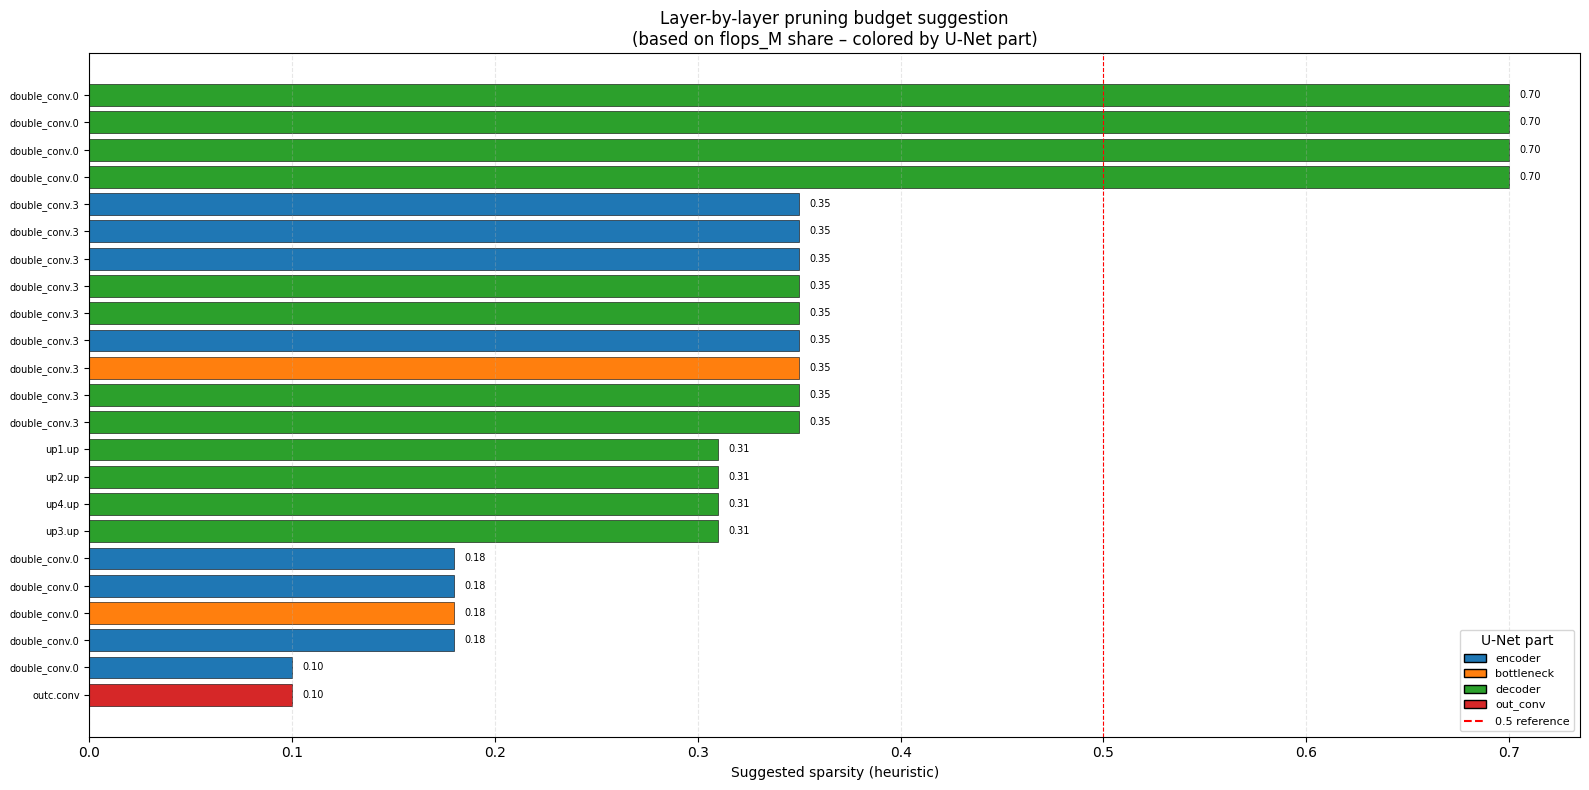

In [18]:
# ── Visualise suggested sparsity ──────────────────────────────────────────
labels = [
    '.'.join(n.split('.')[-2:]) if n.count('.') >= 2 else n
    for n in df_budget['layer_name']
]
colors  = [PART_COLORS.get(p, 'gray') for p in df_budget['part']]
spars   = df_budget['suggested_sparsity'].values

fig, ax = plt.subplots(figsize=(16, 8))
y_pos   = np.arange(len(labels))
bars    = ax.barh(y_pos, spars, color=colors, edgecolor='black', linewidth=0.4)

for bar, v in zip(bars, spars):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
            f'{v:.2f}', va='center', fontsize=7)

ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=7)
ax.invert_yaxis()
ax.set_xlabel('Suggested sparsity (heuristic)')
ax.set_title('Layer-by-layer pruning budget suggestion\n'
             '(based on flops_M share – colored by U-Net part)')
ax.axvline(0.5, color='red', linestyle='--', linewidth=0.8, label='0.5 reference')
ax.grid(axis='x', linestyle='--', alpha=0.3)

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=c, edgecolor='black', label=p)
    for p, c in PART_COLORS.items()
    if p in df_budget['part'].values
]
legend_handles.append(
    plt.Line2D([0], [0], color='red', linestyle='--', label='0.5 reference')
)
ax.legend(handles=legend_handles, loc='lower right', fontsize=8, title='U-Net part')

plt.tight_layout()
plt.show()

### 2.12  Export profiling results

In [19]:
out_path = Path('unet_layer_profiling_results.csv')
df_layers.to_csv(out_path, index=False)
print(f'Saved to {out_path.resolve()}')

budget_path = Path('unet_pruning_budget.csv')
df_budget.to_csv(budget_path, index=False)
print(f'Saved to {budget_path.resolve()}')

Saved to /home/jovyan/cost-based-pruning-layer-by-layer/unet_layer_profiling_results.csv
Saved to /home/jovyan/cost-based-pruning-layer-by-layer/unet_pruning_budget.csv


/tmp/ipykernel_8989/4210051936.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


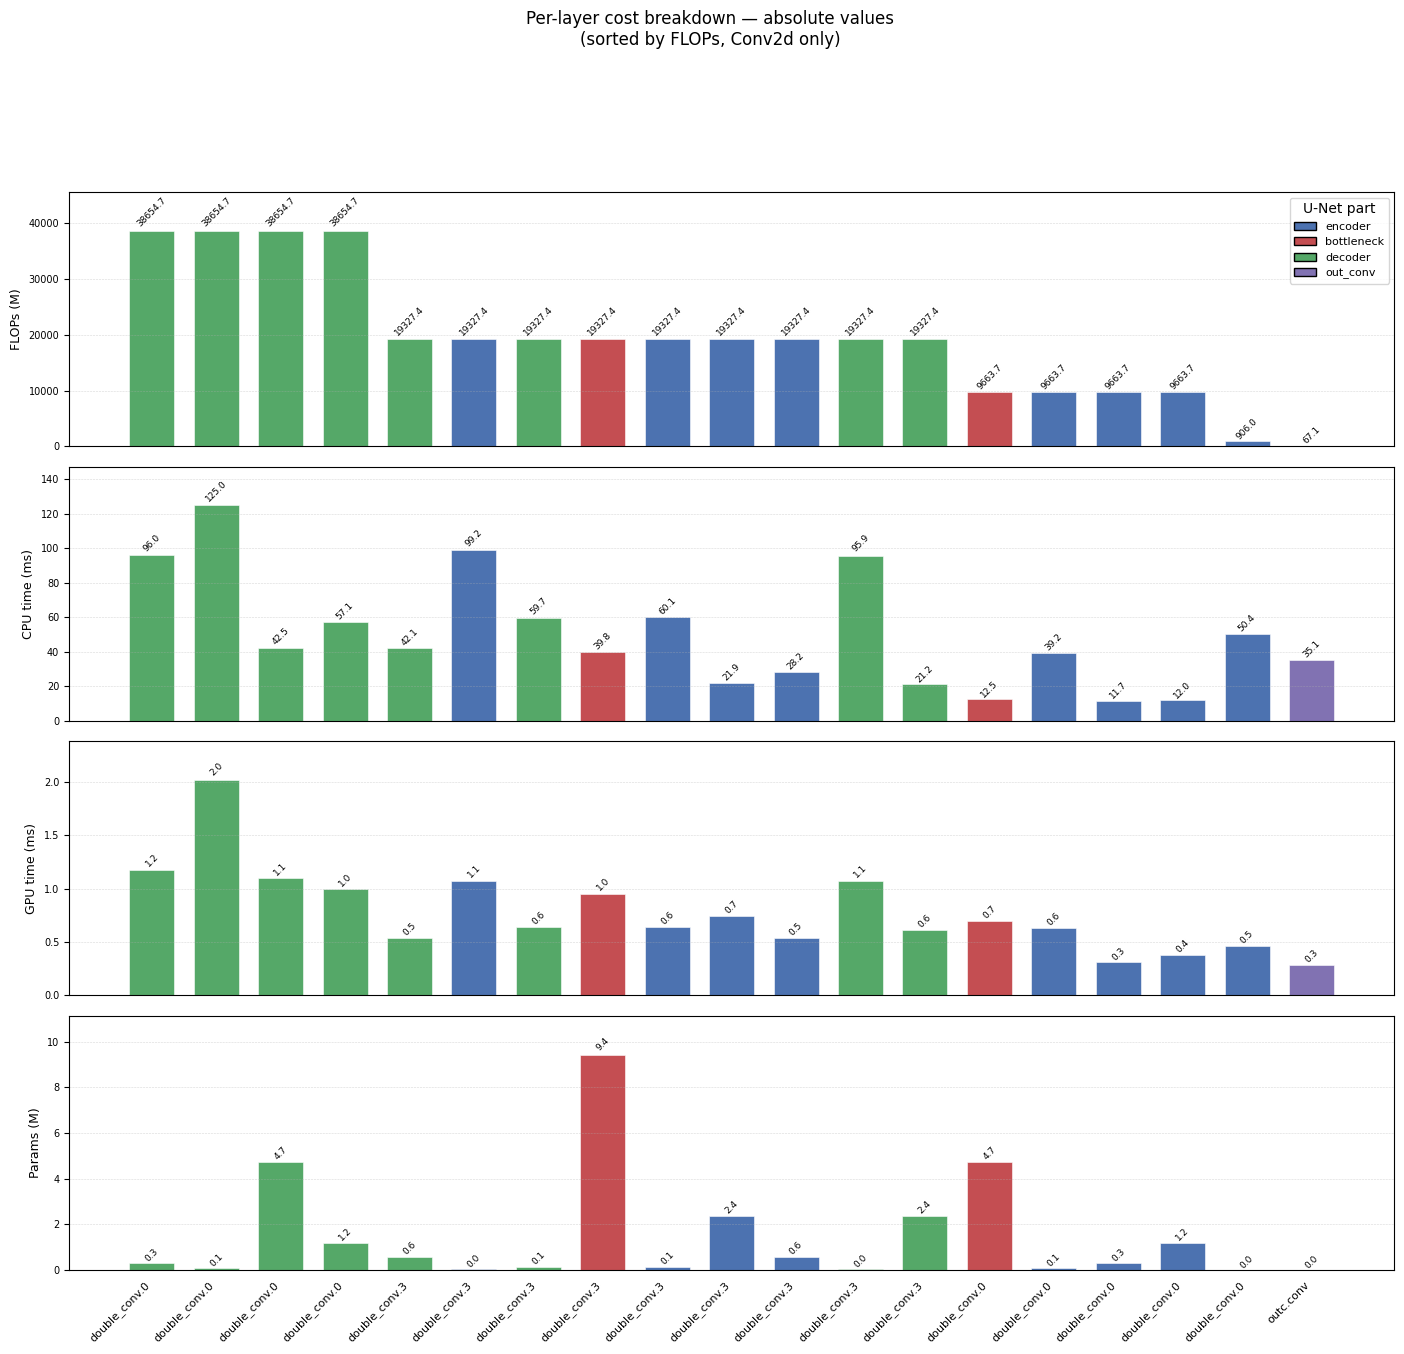

In [20]:
# ── Cell: Combined 4-metric layer overview — absolute values ─────────────────
# Requires: df_layers already built (has layer_name, part, params_M,
#           flops_M, time_gpu_ms, time_cpu_ms)
# ConvTranspose layers are included — filter them out below if you prefer.

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

PART_COLORS = {
    "encoder":    "#4C72B0",
    "bottleneck": "#C44E52",
    "decoder":    "#55A868",
    "out_conv":   "#8172B2",
}

METRICS_ABS = [
    ("flops_M",      "FLOPs (M)",      "steelblue"),
    ("time_cpu_ms",  "CPU time (ms)",   "darkorange"),
    ("time_gpu_ms",  "GPU time (ms)",   "mediumseagreen"),
    ("params_M",     "Params (M)",      "mediumpurple"),
]

# keep only Conv2d layers (the ones your pruner operates on) — toggle if needed
df_plot = df_layers[df_layers["type"] == "Conv2d"].copy()
df_plot = df_plot.sort_values("flops_M", ascending=False).reset_index(drop=True)

short_labels = [
    ".".join(n.split(".")[-2:]) if n.count(".") >= 2 else n
    for n in df_plot["layer_name"]
]
n_layers = len(df_plot)
part_colors = [PART_COLORS.get(p, "gray") for p in df_plot["part"]]

fig, axes = plt.subplots(
    4, 1, figsize=(max(14, n_layers * 0.9), 14),
    sharex=True, gridspec_kw={"hspace": 0.08}
)

for ax, (col, ylabel, color) in zip(axes, METRICS_ABS):
    vals = df_plot[col].values
    bars = ax.bar(np.arange(n_layers), vals, color=part_colors,
                  edgecolor="white", linewidth=0.4, width=0.7)
    # value annotations
    for i, (bar, v) in enumerate(zip(bars, vals)):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.01,
                f"{v:.1f}", ha="center", va="bottom", fontsize=6.5, rotation=45)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
    ax.set_ylim(0, vals.max() * 1.18)
    ax.tick_params(axis="y", labelsize=7)
    ax.tick_params(axis="x", which="both", bottom=False)

axes[-1].set_xticks(np.arange(n_layers))
axes[-1].set_xticklabels(short_labels, rotation=45, ha="right", fontsize=8)

# legend
legend_handles = [
    mpatches.Patch(facecolor=c, edgecolor="black", label=p)
    for p, c in PART_COLORS.items()
    if p in df_plot["part"].values
]
axes[0].legend(handles=legend_handles, loc="upper right",
               fontsize=8, title="U-Net part", framealpha=0.8)

fig.suptitle("Per-layer cost breakdown — absolute values\n"
             "(sorted by FLOPs, Conv2d only)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

/tmp/ipykernel_8989/4275784584.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


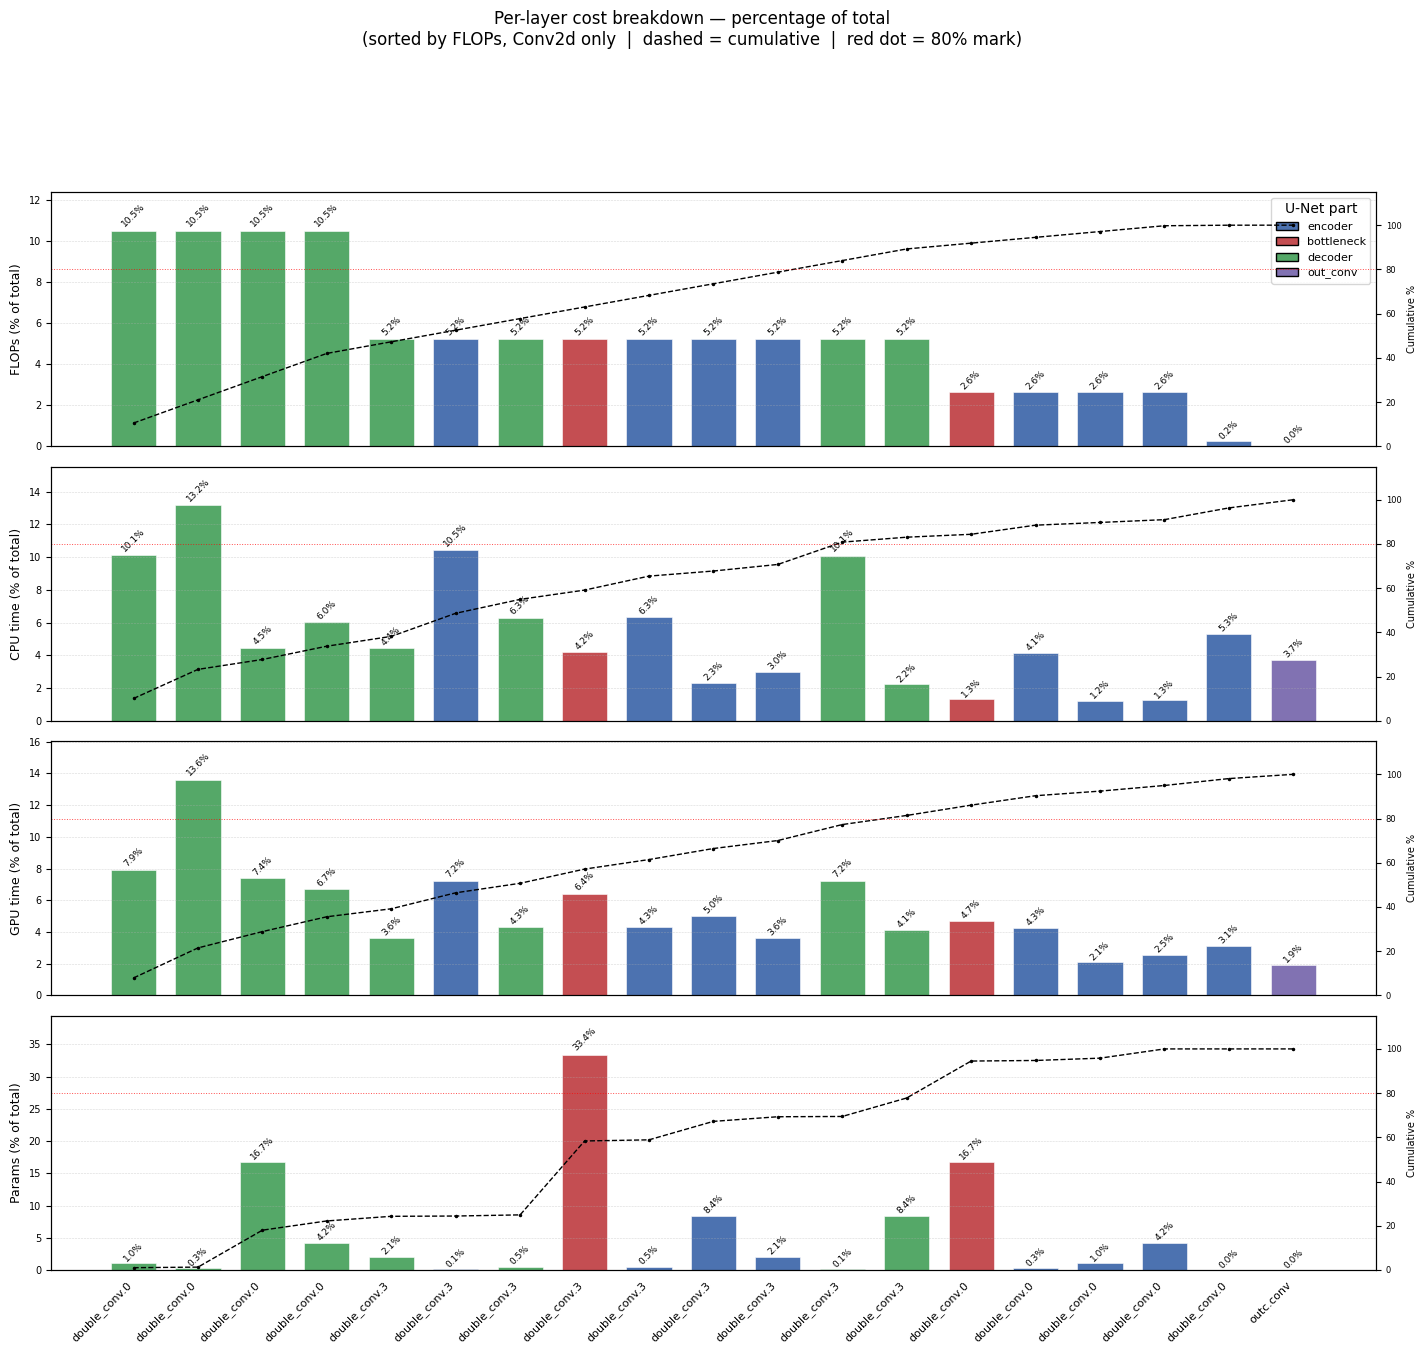

In [21]:
# ── Cell: Combined 4-metric layer overview — percentage of total ──────────────

METRICS_PCT = [
    ("flops_M",      "FLOPs (% of total)",      "steelblue"),
    ("time_cpu_ms",  "CPU time (% of total)",    "darkorange"),
    ("time_gpu_ms",  "GPU time (% of total)",    "mediumseagreen"),
    ("params_M",     "Params (% of total)",      "mediumpurple"),
]

fig, axes = plt.subplots(
    4, 1, figsize=(max(14, n_layers * 0.9), 14),
    sharex=True, gridspec_kw={"hspace": 0.08}
)

for ax, (col, ylabel, color) in zip(axes, METRICS_PCT):
    total = df_plot[col].sum()
    pcts  = df_plot[col].values / total * 100
    bars  = ax.bar(np.arange(n_layers), pcts, color=part_colors,
                   edgecolor="white", linewidth=0.4, width=0.7)
    for bar, v in zip(bars, pcts):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.01,
                f"{v:.1f}%", ha="center", va="bottom", fontsize=6.5, rotation=45)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
    ax.set_ylim(0, pcts.max() * 1.18)
    ax.tick_params(axis="y", labelsize=7)
    ax.tick_params(axis="x", which="both", bottom=False)
    # cumulative line on secondary axis
    ax2 = ax.twinx()
    ax2.plot(np.arange(n_layers), np.cumsum(pcts), color="black",
             lw=1, ls="--", marker=".", ms=3, label="cumulative %")
    ax2.set_ylim(0, 115)
    ax2.set_ylabel("Cumulative %", fontsize=7, color="black")
    ax2.tick_params(axis="y", labelsize=6)
    ax2.axhline(80, color="red", lw=0.7, ls=":", alpha=0.7)   # 80% mark

axes[-1].set_xticks(np.arange(n_layers))
axes[-1].set_xticklabels(short_labels, rotation=45, ha="right", fontsize=8)

legend_handles = [
    mpatches.Patch(facecolor=c, edgecolor="black", label=p)
    for p, c in PART_COLORS.items()
    if p in df_plot["part"].values
]
axes[0].legend(handles=legend_handles, loc="upper right",
               fontsize=8, title="U-Net part", framealpha=0.8)

fig.suptitle("Per-layer cost breakdown — percentage of total\n"
             "(sorted by FLOPs, Conv2d only  |  dashed = cumulative  |  red dot = 80% mark)",
             fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

In [26]:
# ── Cell: print the summary table used by both plots ─────────────────────────
total_flops  = df_plot["flops_M"].sum()
total_cpu    = df_plot["time_cpu_ms"].sum()
total_gpu    = df_plot["time_gpu_ms"].sum()
total_params = df_plot["params_M"].sum()

summary = df_plot[["layer_name", "part", "flops_M",
                    "time_cpu_ms", "time_gpu_ms", "params_M"]].copy()
summary["flops_%"]   = summary["flops_M"]     / total_flops  * 100
summary["cpu_%"]     = summary["time_cpu_ms"] / total_cpu    * 100
summary["gpu_%"]     = summary["time_gpu_ms"] / total_gpu    * 100
summary["params_%"]  = summary["params_M"]    / total_params * 100

print(f"Totals  →  FLOPs: {total_flops/1e3:.2f} G   "
      f"CPU: {total_cpu:.1f} ms   GPU: {total_gpu:.1f} ms   "
      f"Params: {total_params:.3f} M")
print()
print(summary[["layer_name", "part",
               "flops_M", "flops_%",
               "time_cpu_ms", "cpu_%",
               "time_gpu_ms", "gpu_%",
               "params_M", "params_%"]]
      .to_string(index=False, float_format=lambda x: f"{x:.2f}"))

# ── Sum of percentages per part (sanity check) ─────────────────────────────
part_summary = (
    summary
    .groupby("part")[["flops_%", "params_%"]]
    .sum()
    .reset_index()
)

print("\nPercentage sums by part (should each sum to ~100% across all parts):\n")
print(part_summary.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

Totals  →  FLOPs: 368.19 G   CPU: 949.6 ms   GPU: 14.9 ms   Params: 28.240 M

                        layer_name       part  flops_M  flops_%  time_cpu_ms  cpu_%  time_gpu_ms  gpu_%  params_M  params_%
            up3.conv.double_conv.0    decoder 38654.71    10.50        96.03  10.11         1.17   7.90      0.29      1.04
            up4.conv.double_conv.0    decoder 38654.71    10.50       124.99  13.16         2.02  13.59      0.07      0.26
            up1.conv.double_conv.0    decoder 38654.71    10.50        42.46   4.47         1.10   7.38      4.72     16.71
            up2.conv.double_conv.0    decoder 38654.71    10.50        57.11   6.01         1.00   6.71      1.18      4.18
            up2.conv.double_conv.3    decoder 19327.35     5.25        42.08   4.43         0.54   3.61      0.59      2.09
                 inc.double_conv.3    encoder 19327.35     5.25        99.24  10.45         1.07   7.23      0.04      0.13
            up3.conv.double_conv.3    decoder 19327.35